<a href="https://www.kaggle.com/code/lalit7881/airbnb-listing-demand-prediction-100?scriptVersionId=375359816" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vedauv/what-makes-an-airbnb-listing-sell-out-10k-stays/README.md
/kaggle/input/datasets/vedauv/what-makes-an-airbnb-listing-sell-out-10k-stays/datasheet.md
/kaggle/input/datasets/vedauv/what-makes-an-airbnb-listing-sell-out-10k-stays/stay_listings.csv


## Loading dataset

In [2]:
df = pd.read_csv('/kaggle/input/datasets/vedauv/what-makes-an-airbnb-listing-sell-out-10k-stays/stay_listings.csv')

In [3]:
df.head()

,listing_id,city,property_type,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,...,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
0,L00001,Mexico City,Entire home,2,1.5,5,7.1,52.0,17.0,1,...,6.9,27,23,0,30,4.59,3,61.3,11500.0,0
1,L00002,Paris,Entire home,1,1.0,3,4.6,147.0,52.0,0,...,1.4,13,20,1,7,4.61,7,23.7,11300.0,0
2,L00003,New York,Entire home,2,2.0,5,1.6,131.0,36.0,0,...,5.1,18,35,0,30,4.64,6,45.8,21700.0,0
3,L00004,Tokyo,Entire home,2,1.5,5,5.7,164.0,68.0,0,...,3.6,36,43,0,2,4.71,20,42.6,25300.0,0
4,L00005,Berlin,Entire home,3,2.0,8,4.6,321.0,32.0,1,...,5.6,27,48,1,5,4.98,28,65.1,74500.0,0


In [4]:
df.tail()

,listing_id,city,property_type,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,...,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
9995,L09996,Berlin,Private room,1,1.5,4,1.4,43.0,16.0,1,...,1.0,3,25,1,5,4.44,17,43.1,6300.0,0
9996,L09997,Sydney,Entire home,2,2.0,6,4.7,80.0,39.0,0,...,4.1,8,15,0,1,4.22,6,14.3,4000.0,0
9997,L09998,London,Entire home,2,2.0,6,1.9,215.0,29.0,0,...,0.5,20,42,0,2,4.82,25,52.2,39100.0,0
9998,L09999,London,Entire home,2,2.0,6,3.1,109.0,48.0,0,...,0.4,14,31,0,2,4.45,39,30.4,11800.0,0
9999,L10000,Lisbon,Private room,1,1.5,4,9.1,22.0,7.0,1,...,0.7,41,12,0,1,4.40,59,61.7,4800.0,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           10000 non-null  object 
 1   city                 10000 non-null  object 
 2   property_type        10000 non-null  object 
 3   bedrooms             10000 non-null  int64  
 4   bathrooms            10000 non-null  float64
 5   guest_capacity       10000 non-null  int64  
 6   distance_center_km   10000 non-null  float64
 7   price_per_night_usd  10000 non-null  float64
 8   cleaning_fee_usd     10000 non-null  float64
 9   superhost            10000 non-null  int64  
 10  host_response_rate   10000 non-null  float64
 11  host_years           10000 non-null  float64
 12  photo_count          10000 non-null  int64  
 13  amenities_count      10000 non-null  int64  
 14  instant_book         10000 non-null  int64  
 15  min_nights           10000 non-null  

In [6]:
df.describe()

,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,host_response_rate,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.0000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.406600,1.563800,4.327500,4.109520,91.666300,27.487600,0.361700,91.728000,3.175140,22.053600,28.208400,0.4460,5.056100,4.599185,49.210400,52.994650,16125.830000,0.250400
std,0.936143,0.499354,1.942375,3.730051,45.596351,18.061541,0.480517,5.791474,2.822191,9.268696,9.509943,0.4971,8.383781,0.188447,43.691224,19.478673,9699.187762,0.433265
min,0.000000,0.500000,1.000000,0.200000,18.000000,2.000000,0.000000,66.000000,0.200000,3.000000,3.000000,0.0000,1.000000,3.880000,0.000000,3.000000,400.000000,0.000000
25%,1.000000,1.000000,3.000000,1.800000,59.000000,15.000000,0.000000,88.000000,1.100000,16.000000,22.000000,0.0000,1.000000,4.470000,18.000000,39.600000,9500.000000,0.000000
50%,1.000000,1.500000,4.000000,3.000000,82.000000,23.000000,0.000000,92.000000,2.300000,22.000000,28.000000,0.0000,2.000000,4.600000,38.000000,52.900000,13950.000000,0.000000
75%,2.000000,2.000000,5.000000,5.100000,114.000000,36.000000,1.000000,96.000000,4.400000,28.000000,35.000000,1.0000,3.000000,4.730000,67.000000,66.600000,20500.000000,1.000000
max,4.000000,3.500000,10.000000,30.000000,414.000000,164.000000,1.000000,100.000000,14.000000,55.000000,65.000000,1.0000,30.000000,5.000000,417.000000,98.000000,85500.000000,1.000000


In [7]:
df.isnull().sum()

listing_id             0
city                   0
property_type          0
bedrooms               0
bathrooms              0
guest_capacity         0
distance_center_km     0
price_per_night_usd    0
cleaning_fee_usd       0
superhost              0
host_response_rate     0
host_years             0
photo_count            0
amenities_count        0
instant_book           0
min_nights             0
review_score           0
reviews_count          0
occupancy_rate_pct     0
annual_revenue_usd     0
high_demand            0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

listing_id              object
city                    object
property_type           object
bedrooms                 int64
bathrooms              float64
guest_capacity           int64
distance_center_km     float64
price_per_night_usd    float64
cleaning_fee_usd       float64
superhost                int64
host_response_rate     float64
host_years             float64
photo_count              int64
amenities_count          int64
instant_book             int64
min_nights               int64
review_score           float64
reviews_count            int64
occupancy_rate_pct     float64
annual_revenue_usd     float64
high_demand              int64
dtype: object

In [10]:
df.shape

(10000, 21)

In [11]:
df.columns

Index(['listing_id', 'city', 'property_type', 'bedrooms', 'bathrooms',
       'guest_capacity', 'distance_center_km', 'price_per_night_usd',
       'cleaning_fee_usd', 'superhost', 'host_response_rate', 'host_years',
       'photo_count', 'amenities_count', 'instant_book', 'min_nights',
       'review_score', 'reviews_count', 'occupancy_rate_pct',
       'annual_revenue_usd', 'high_demand'],
      dtype='object')

In [12]:
df.nunique()

listing_id             10000
city                      12
property_type              4
bedrooms                   5
bathrooms                  7
guest_capacity            10
distance_center_km       234
price_per_night_usd      286
cleaning_fee_usd         131
superhost                  2
host_response_rate        34
host_years               139
photo_count               53
amenities_count           60
instant_book               2
min_nights                 6
review_score             108
reviews_count            268
occupancy_rate_pct       930
annual_revenue_usd       553
high_demand                2
dtype: int64

## EDA

DATASET INFORMATION

Dataset Shape: (10000, 21)

First 5 Rows:


,listing_id,city,property_type,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,...,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
0,L00001,Mexico City,Entire home,2,1.5,5,7.1,52.0,17.0,1,...,6.9,27,23,0,30,4.59,3,61.3,11500.0,0
1,L00002,Paris,Entire home,1,1.0,3,4.6,147.0,52.0,0,...,1.4,13,20,1,7,4.61,7,23.7,11300.0,0
2,L00003,New York,Entire home,2,2.0,5,1.6,131.0,36.0,0,...,5.1,18,35,0,30,4.64,6,45.8,21700.0,0
3,L00004,Tokyo,Entire home,2,1.5,5,5.7,164.0,68.0,0,...,3.6,36,43,0,2,4.71,20,42.6,25300.0,0
4,L00005,Berlin,Entire home,3,2.0,8,4.6,321.0,32.0,1,...,5.6,27,48,1,5,4.98,28,65.1,74500.0,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           10000 non-null  object 
 1   city                 10000 non-null  object 
 2   property_type        10000 non-null  object 
 3   bedrooms             10000 non-null  int64  
 4   bathrooms            10000 non-null  float64
 5   guest_capacity       10000 non-null  int64  
 6   distance_center_km   10000 non-null  float64
 7   price_per_night_usd  10000 non-null  float64
 8   cleaning_fee_usd     10000 non-null  float64
 9   superhost            10000 non-null  int64  
 10  host_response_rate   10000 non-null  float64
 11  host_years           10000 non-null  float64
 12  photo_count          10000 non-null  int64  
 13  amenities_count      10000 non-null  int64  
 14  instant_book         10000 non-null  int64  
 15  min_nights     

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
listing_id,10000,10000,L09984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,10000,12,New York,1237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
property_type,10000,4,Entire home,5895,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bedrooms,10000.0,NaN,NaN,NaN,1.4066,0.936143,0.0,1.0,1.0,2.0,4.0
bathrooms,10000.0,NaN,NaN,NaN,1.5638,0.499354,0.5,1.0,1.5,2.0,3.5
guest_capacity,10000.0,NaN,NaN,NaN,4.3275,1.942375,1.0,3.0,4.0,5.0,10.0
distance_center_km,10000.0,NaN,NaN,NaN,4.10952,3.730051,0.2,1.8,3.0,5.1,30.0
price_per_night_usd,10000.0,NaN,NaN,NaN,91.6663,45.596351,18.0,59.0,82.0,114.0,414.0
cleaning_fee_usd,10000.0,NaN,NaN,NaN,27.4876,18.061541,2.0,15.0,23.0,36.0,164.0
superhost,10000.0,NaN,NaN,NaN,0.3617,0.480517,0.0,0.0,0.0,1.0,1.0



Missing Values:


listing_id             0
city                   0
property_type          0
bedrooms               0
bathrooms              0
guest_capacity         0
distance_center_km     0
price_per_night_usd    0
cleaning_fee_usd       0
superhost              0
host_response_rate     0
host_years             0
photo_count            0
amenities_count        0
instant_book           0
min_nights             0
review_score           0
reviews_count          0
occupancy_rate_pct     0
annual_revenue_usd     0
high_demand            0
dtype: int64


Duplicate Rows: 0


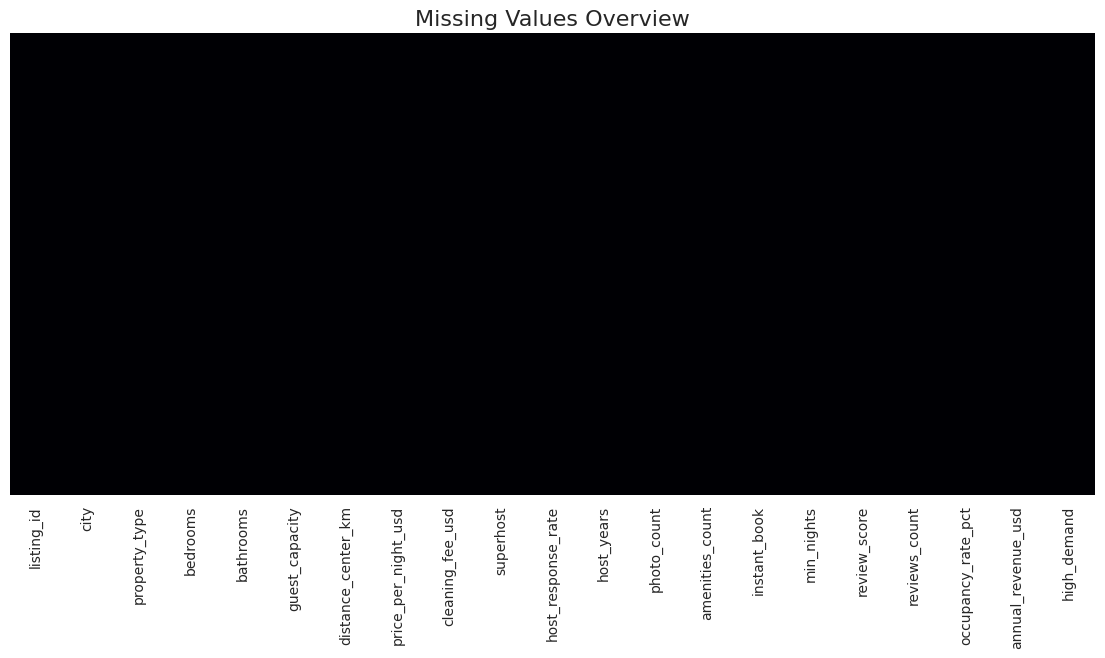

No missing values found.


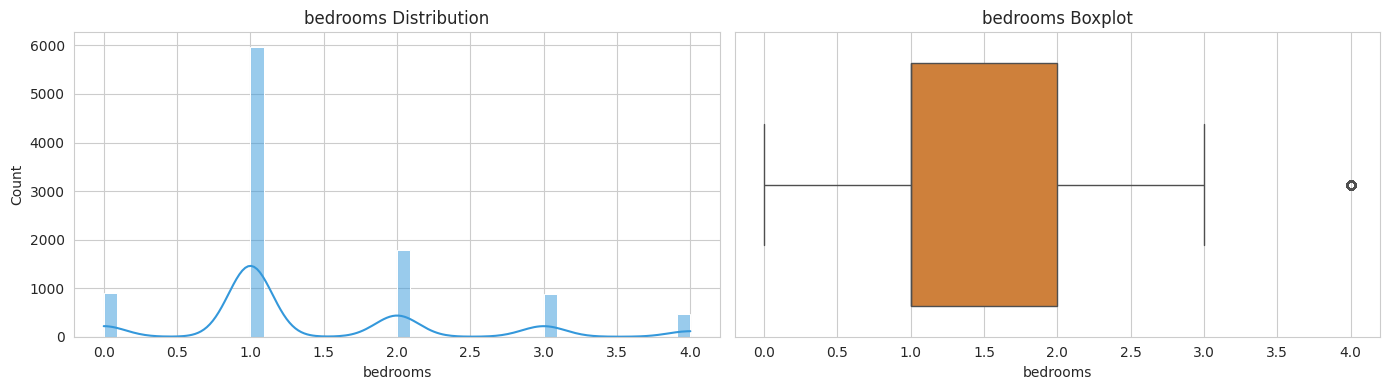

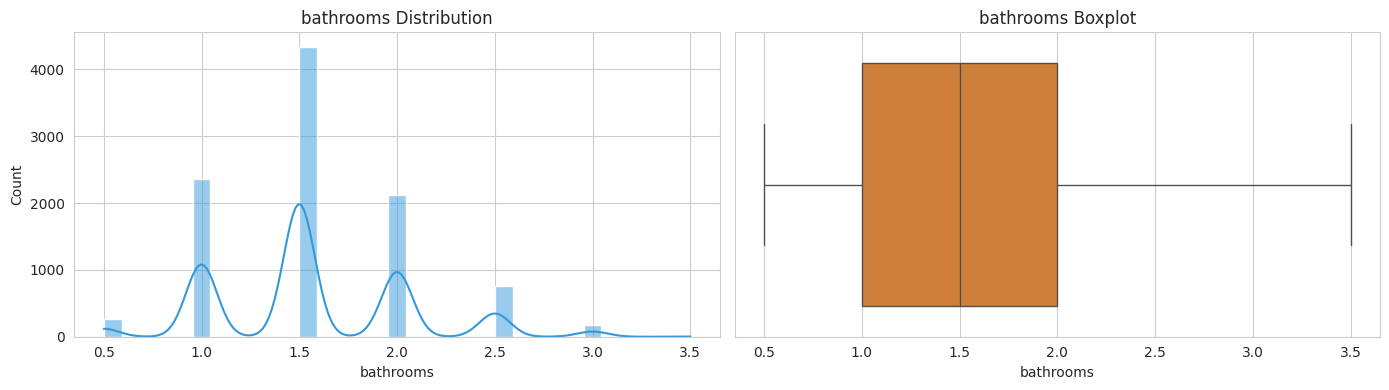

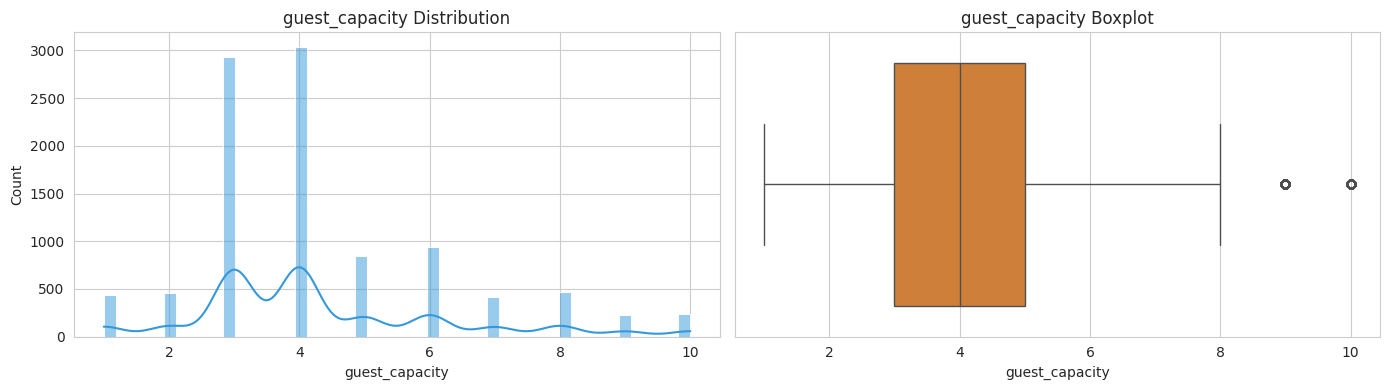

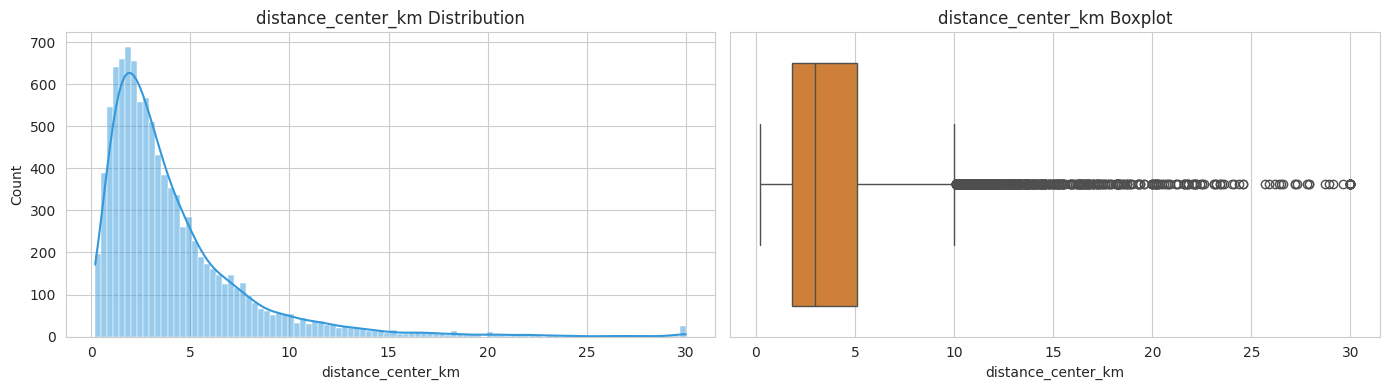

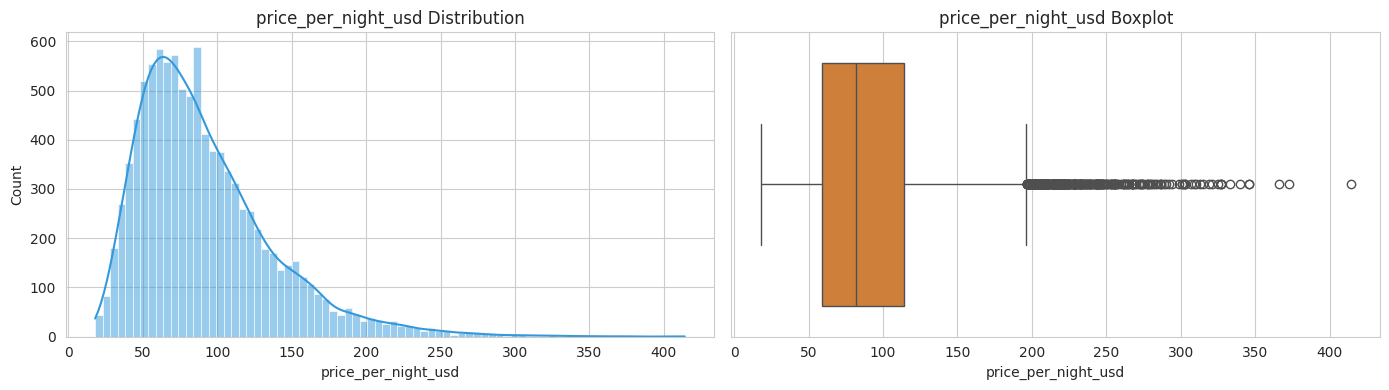

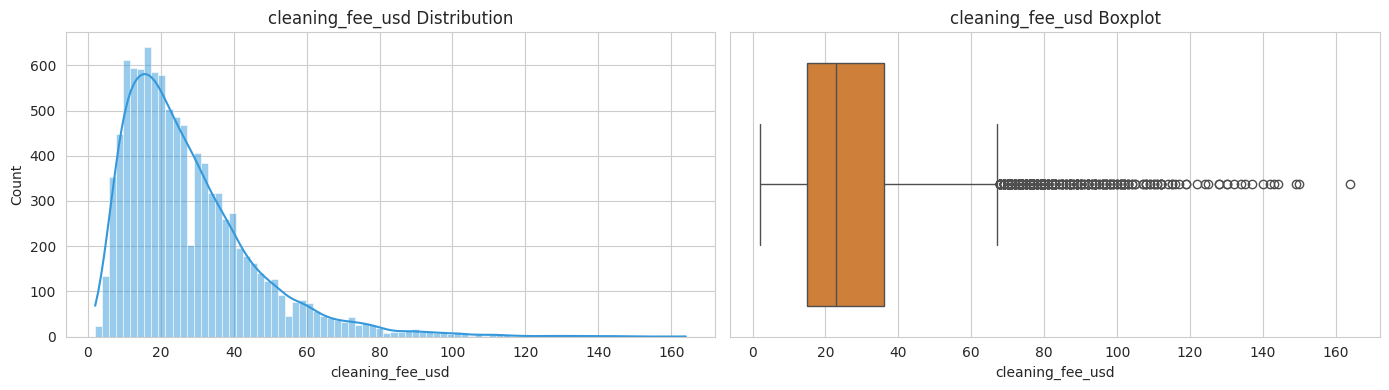

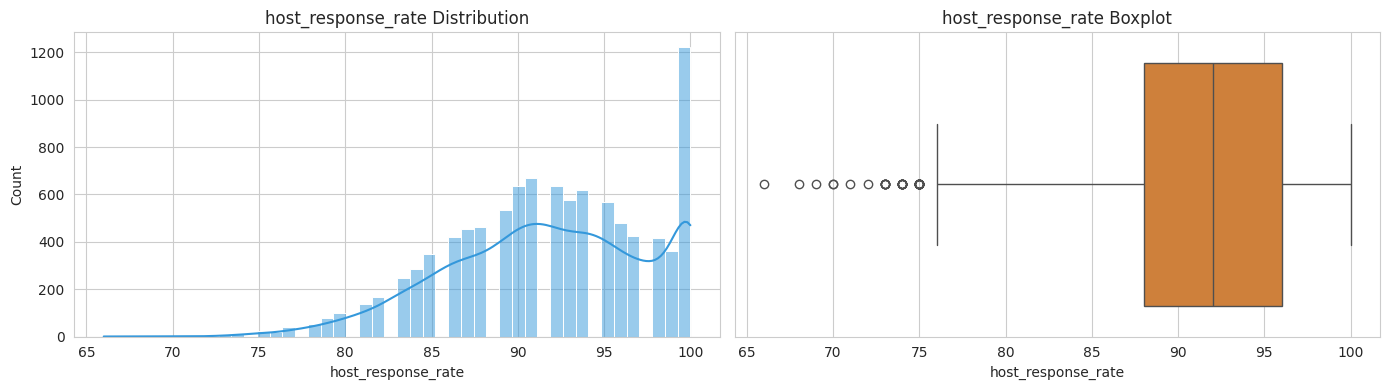

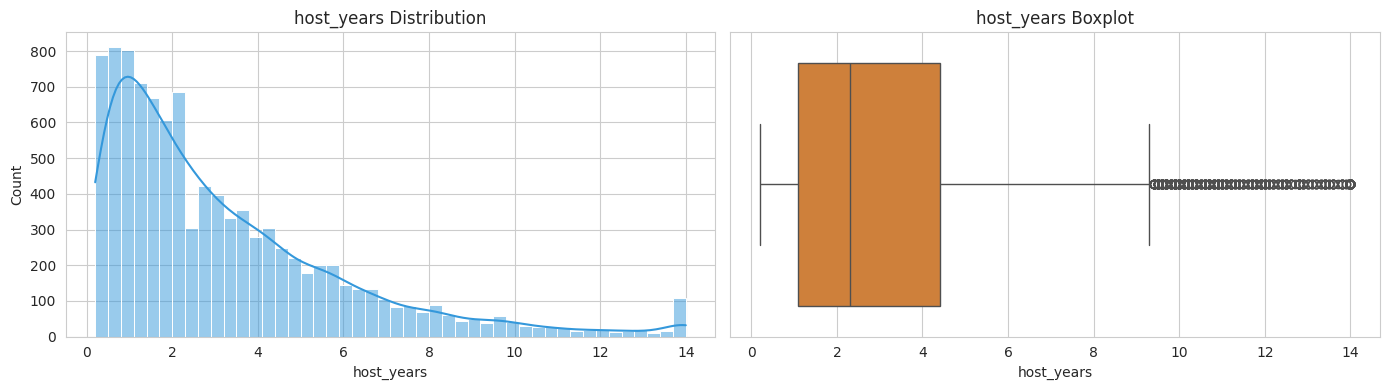

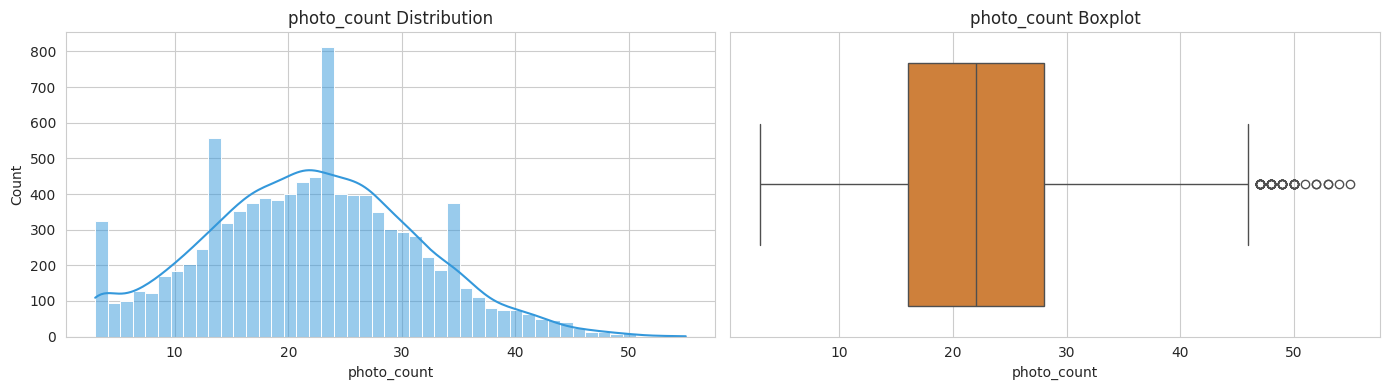

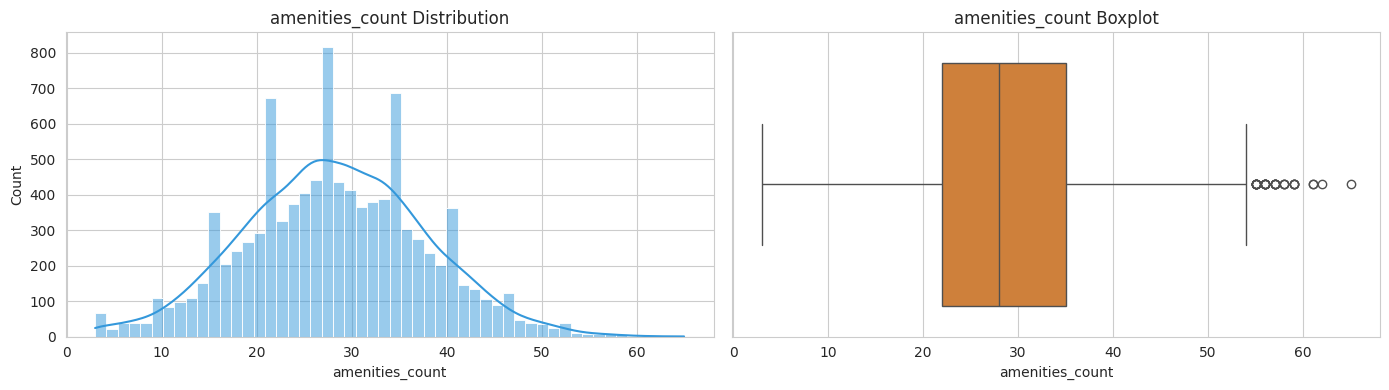

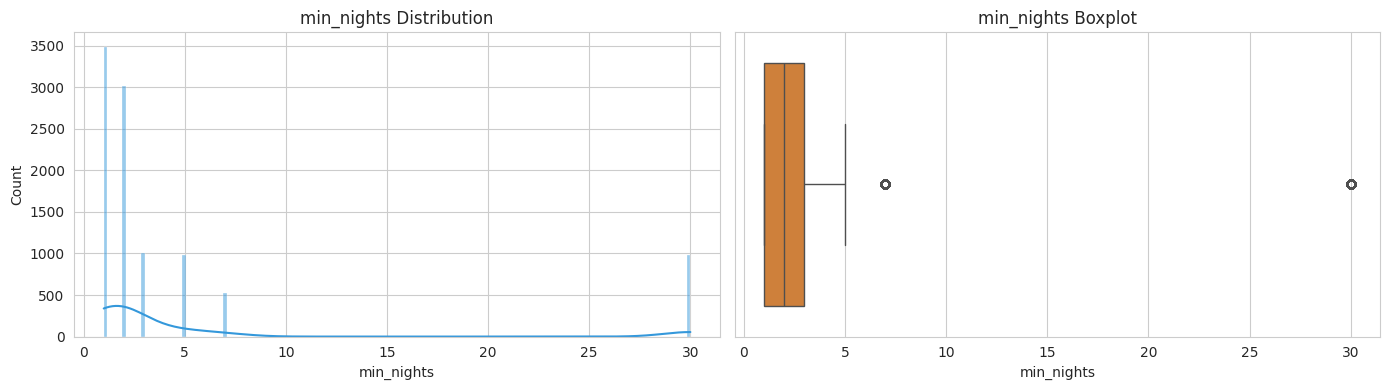

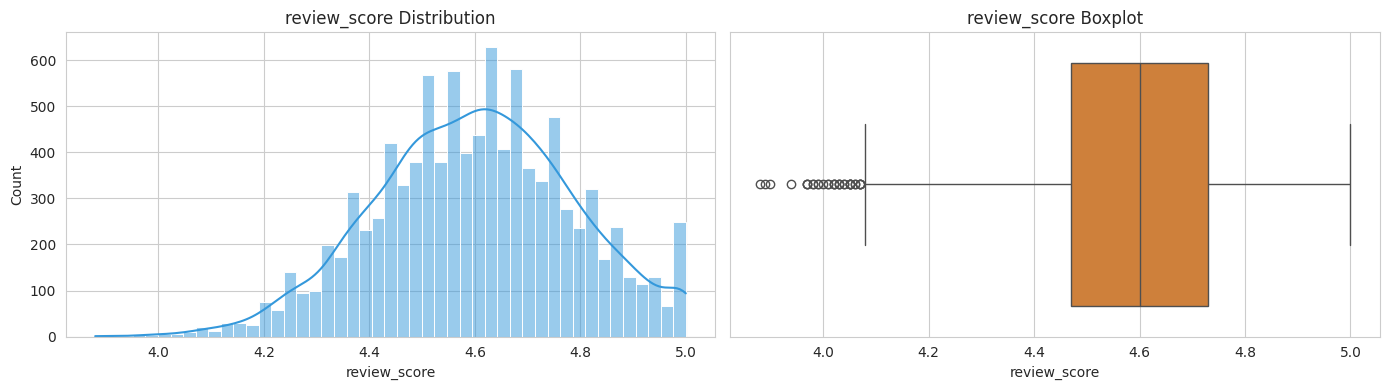

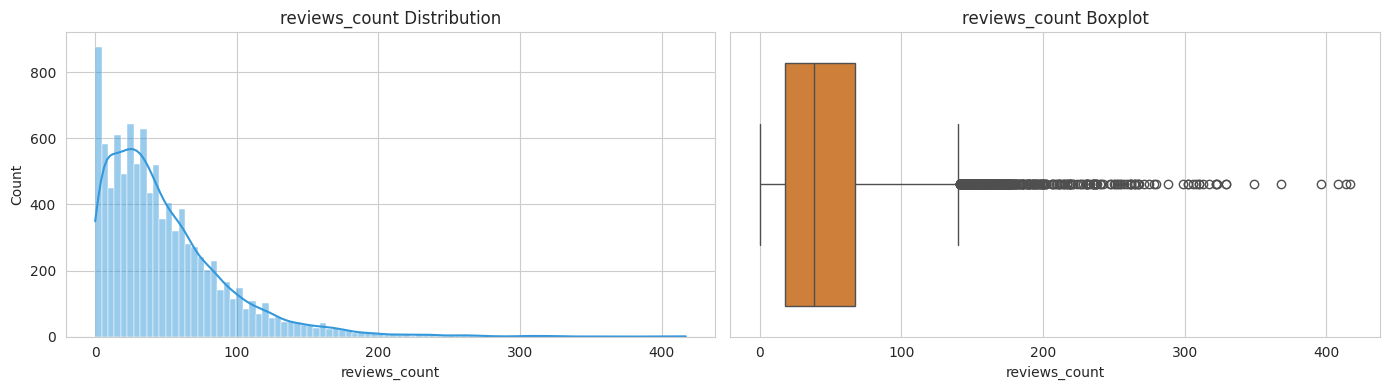

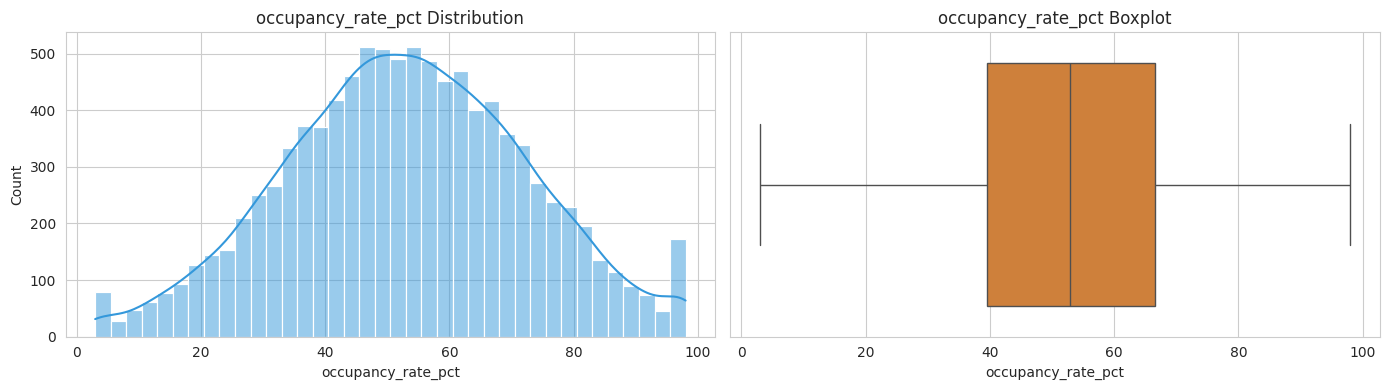

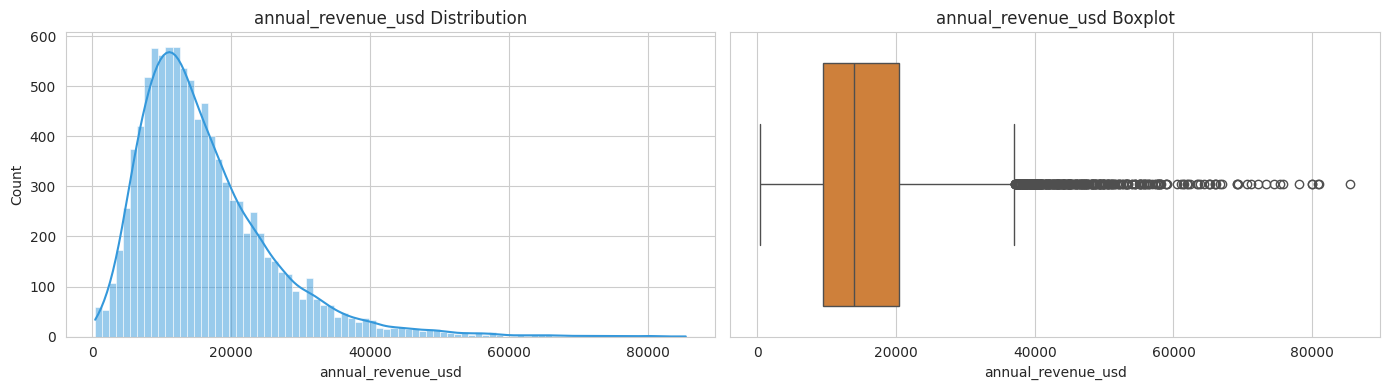

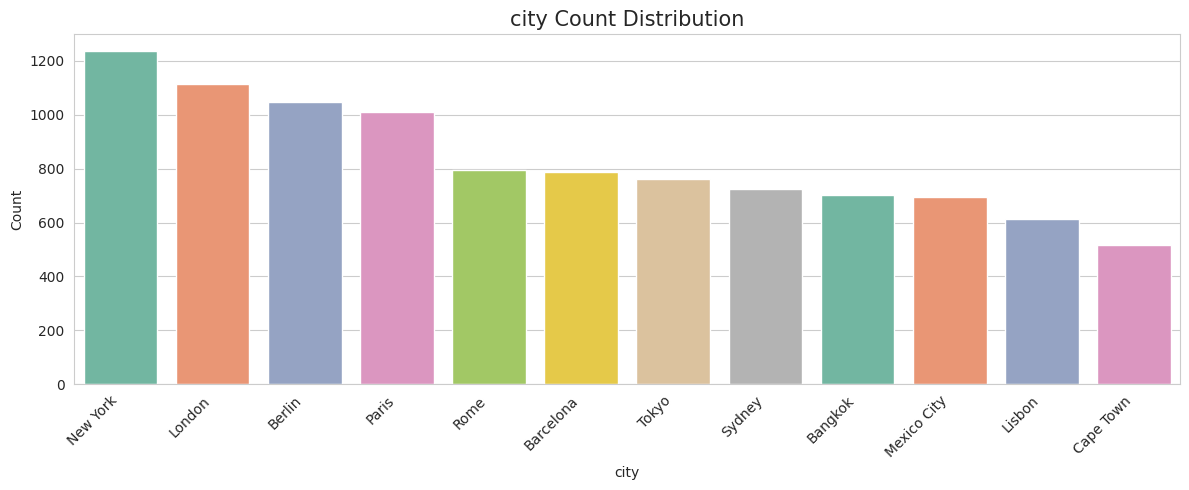

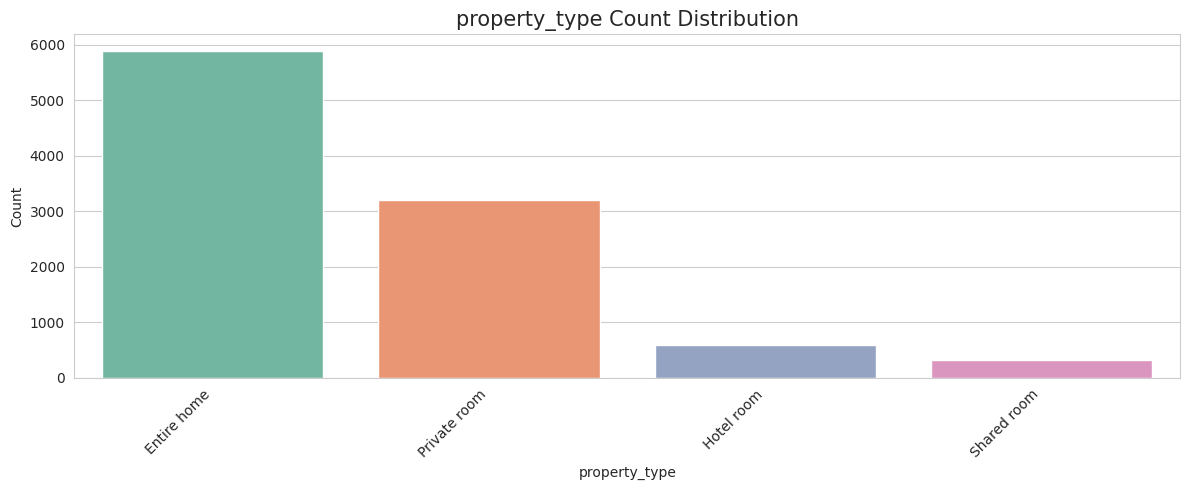

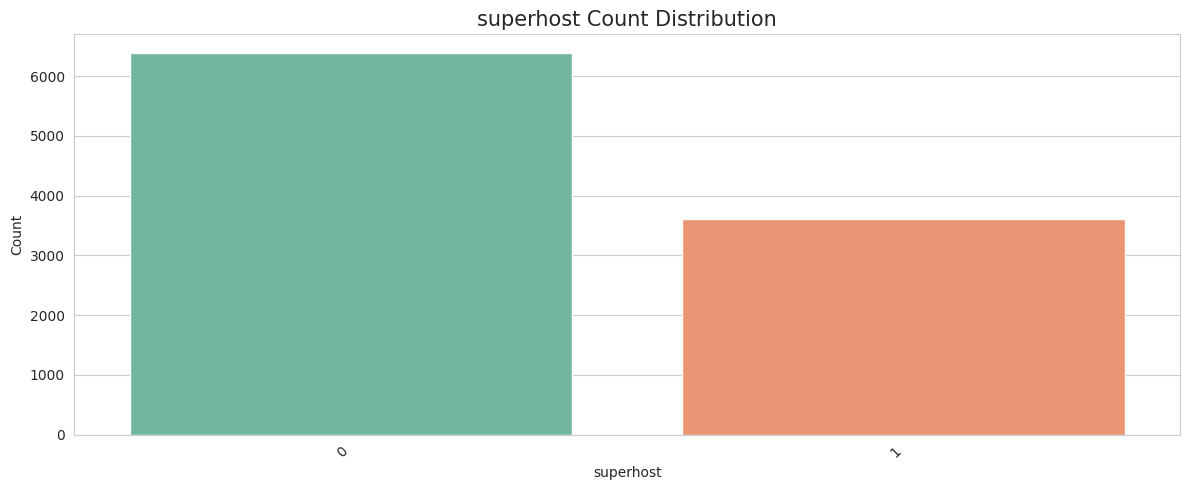

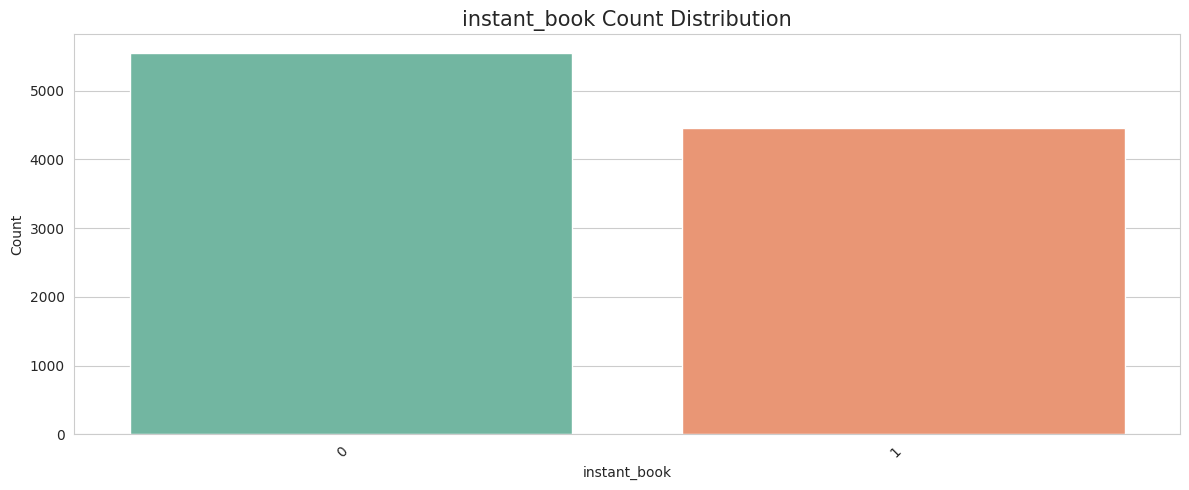

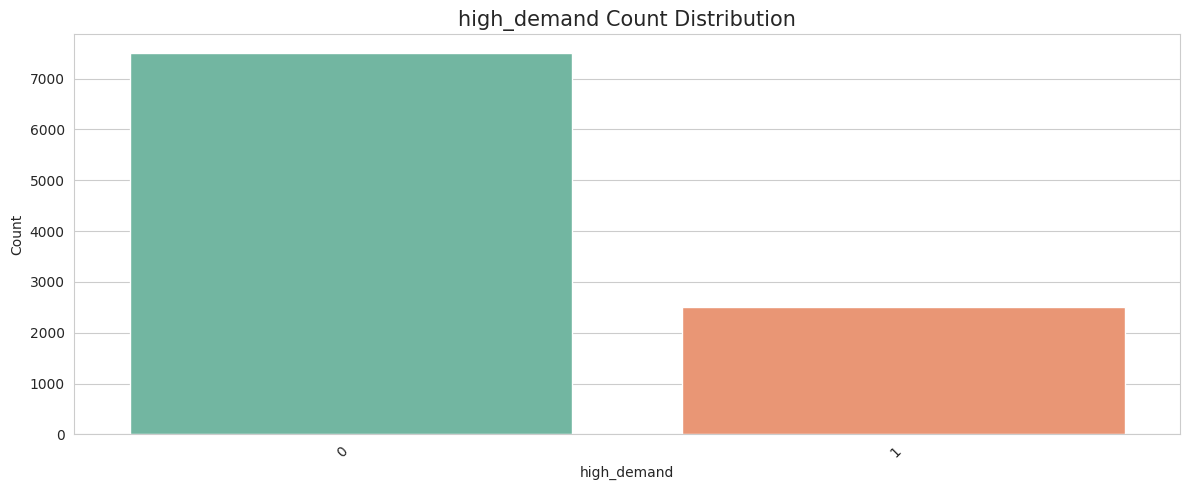

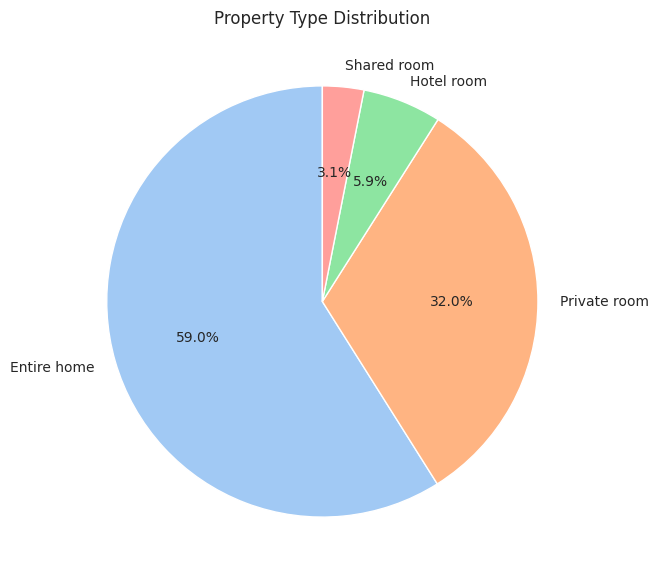

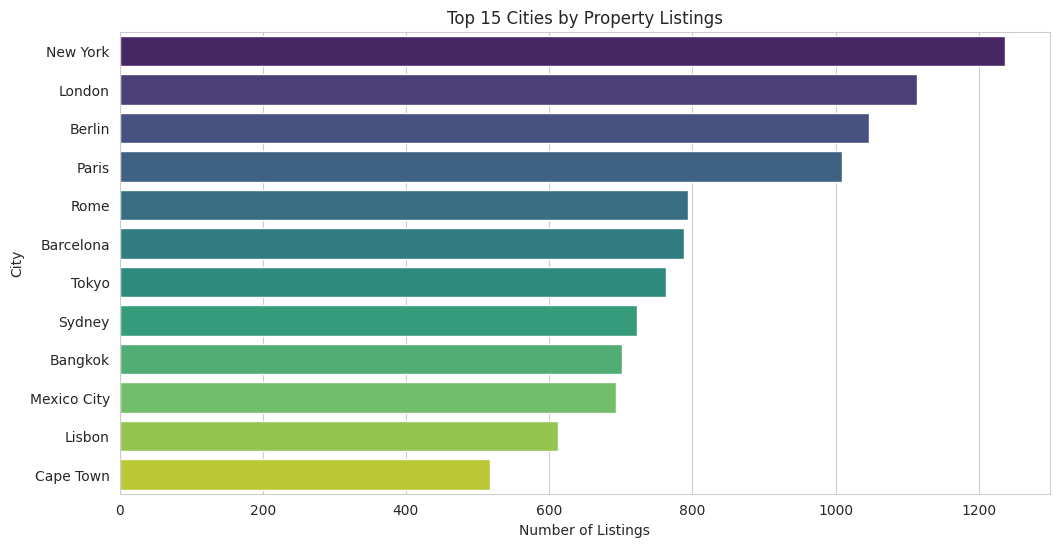

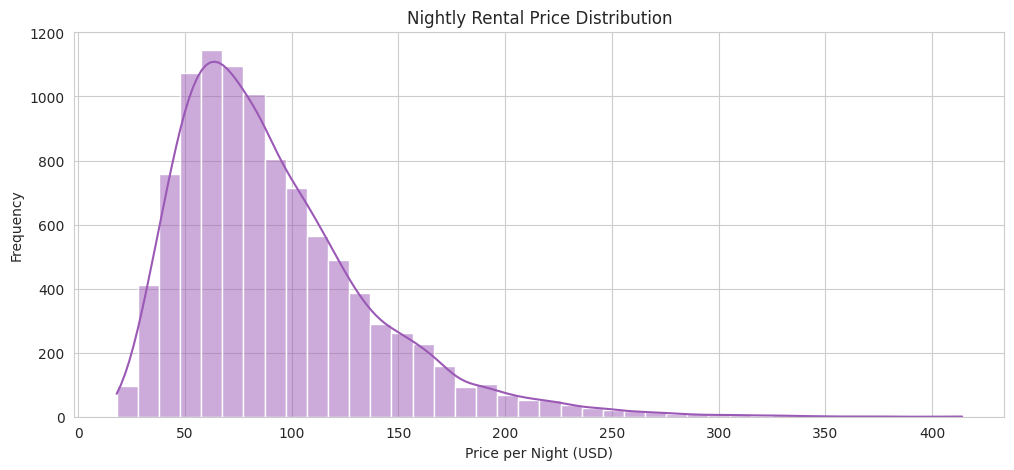

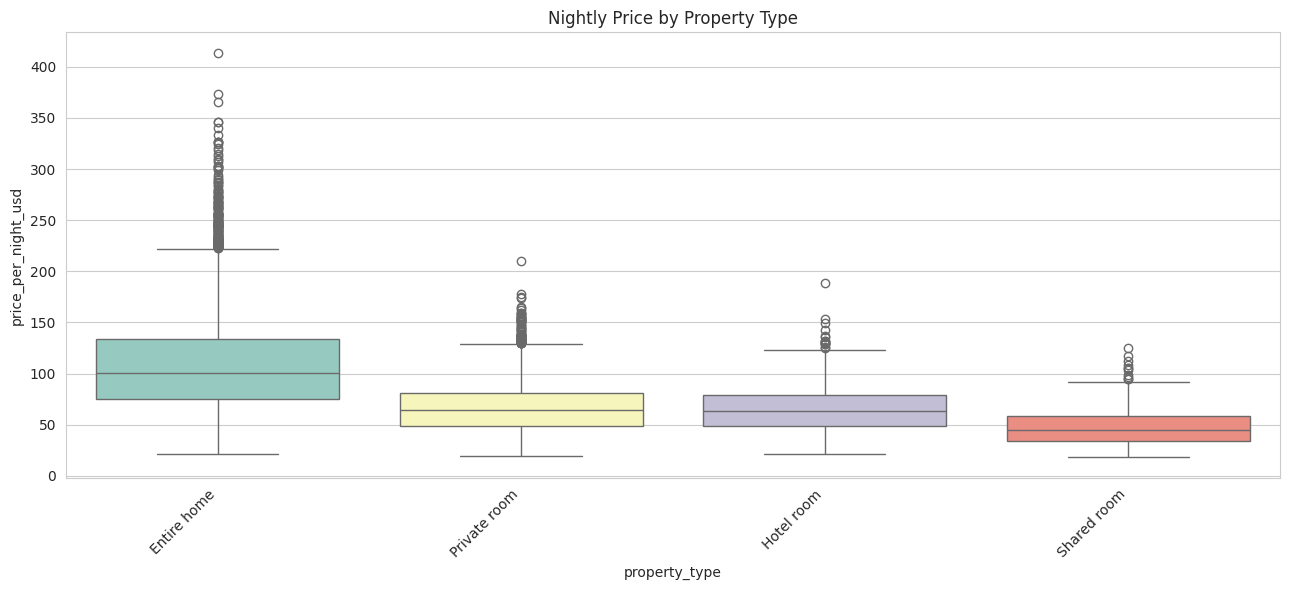

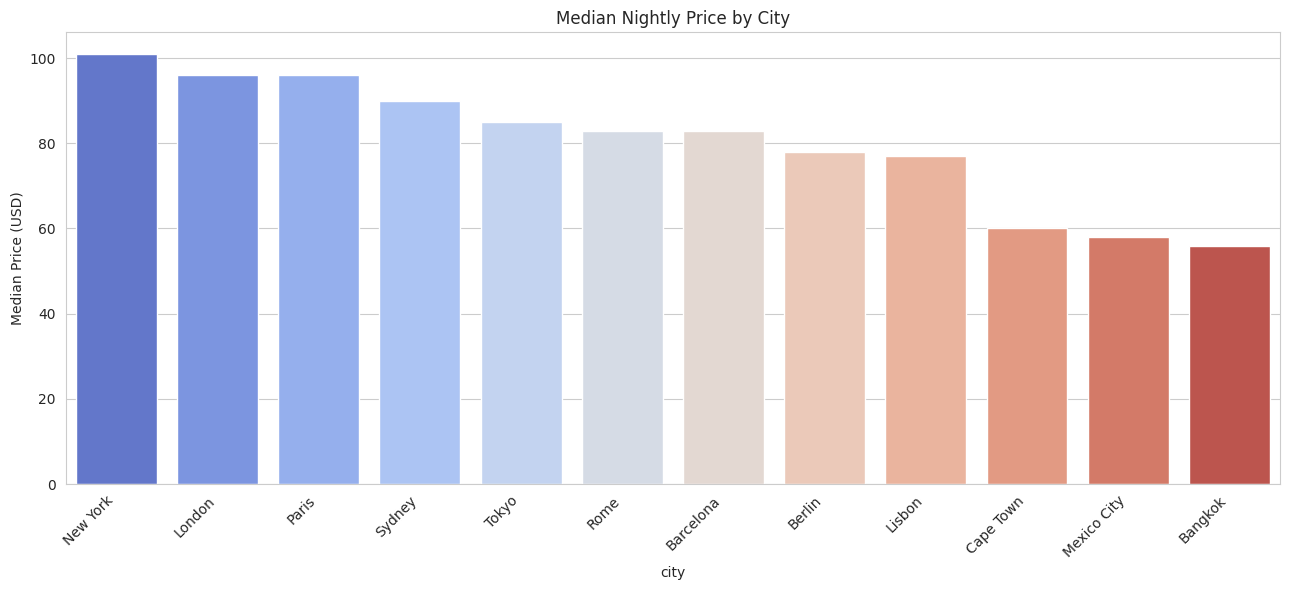

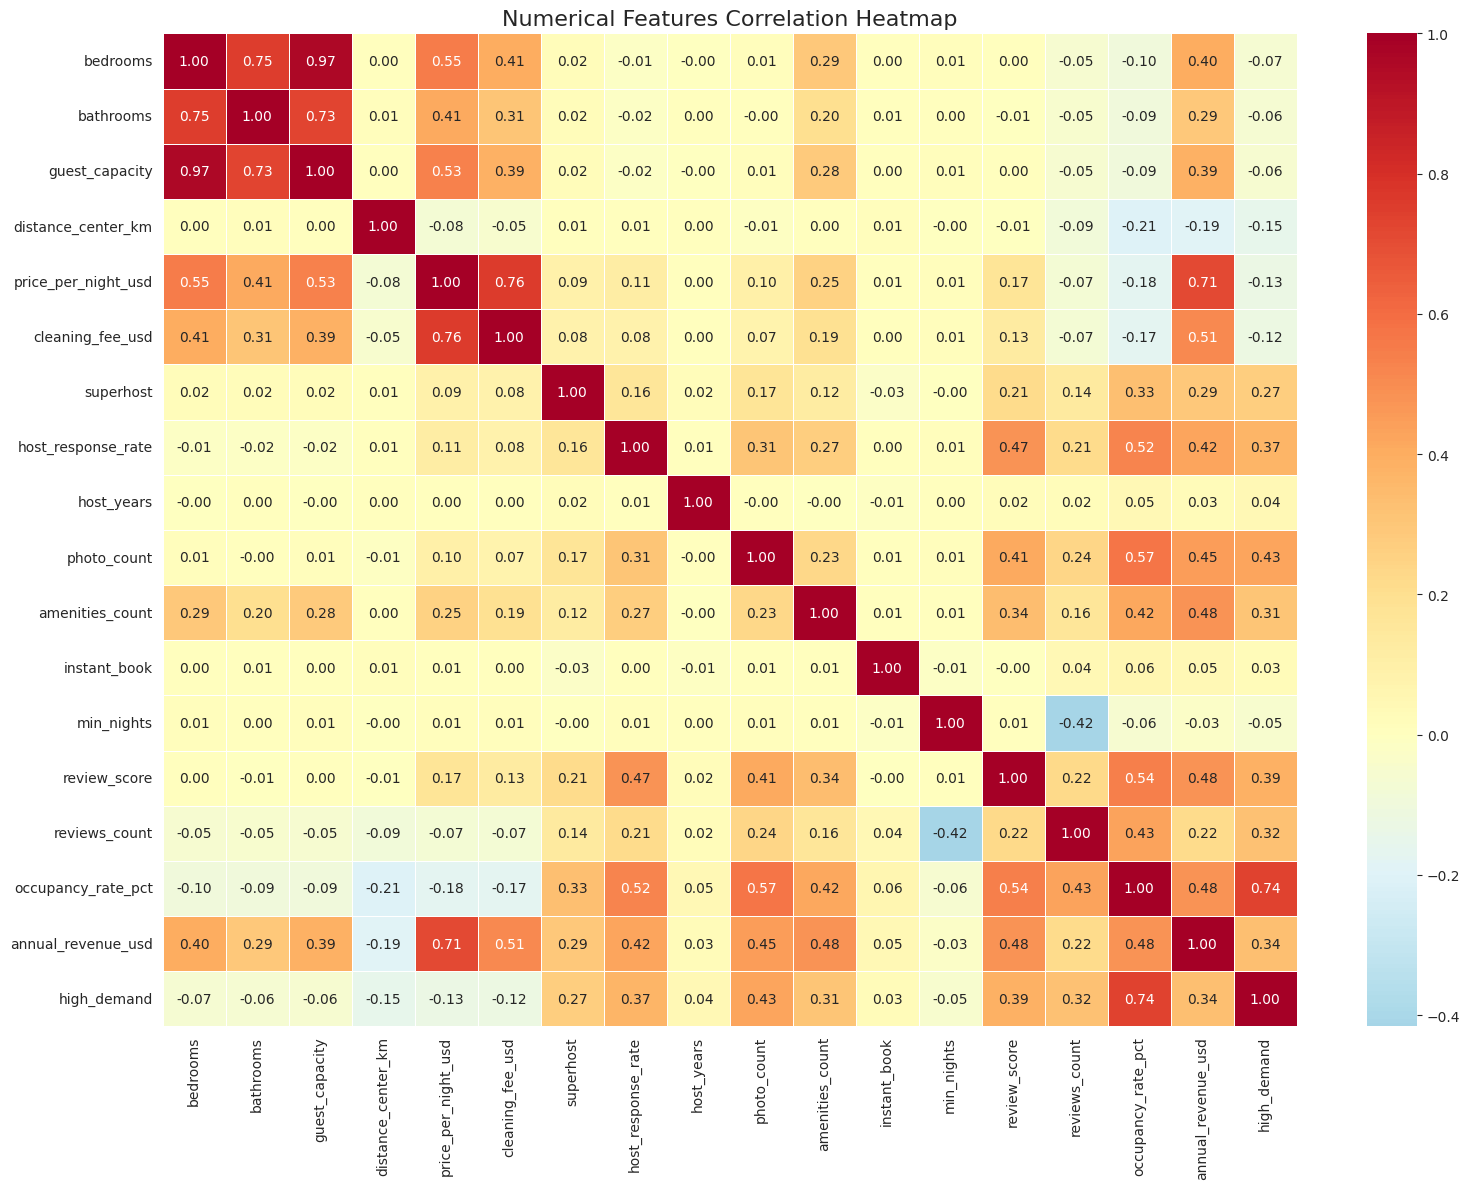

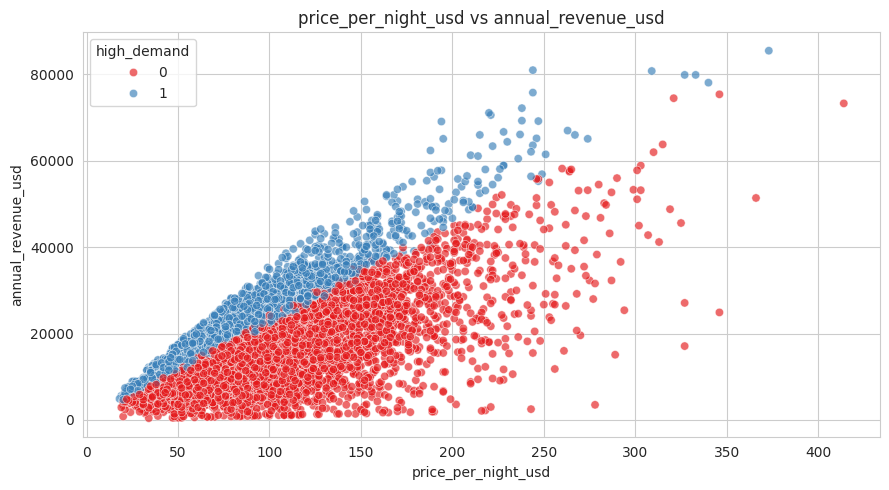

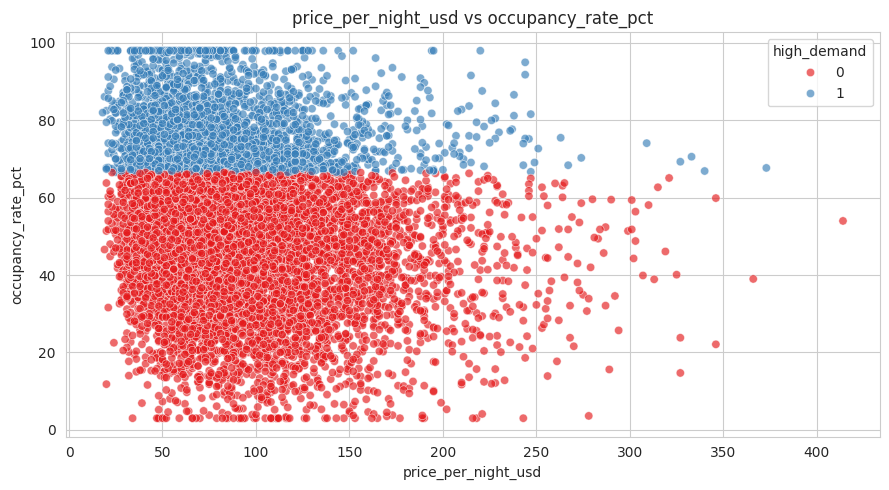

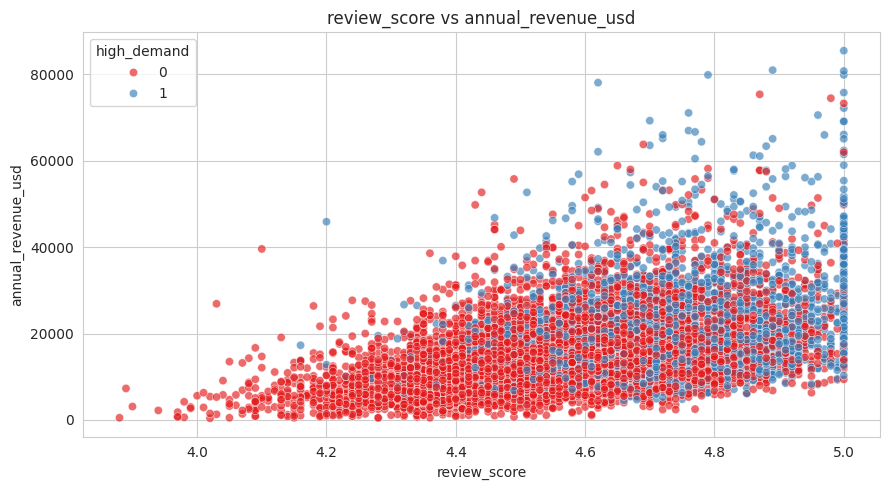

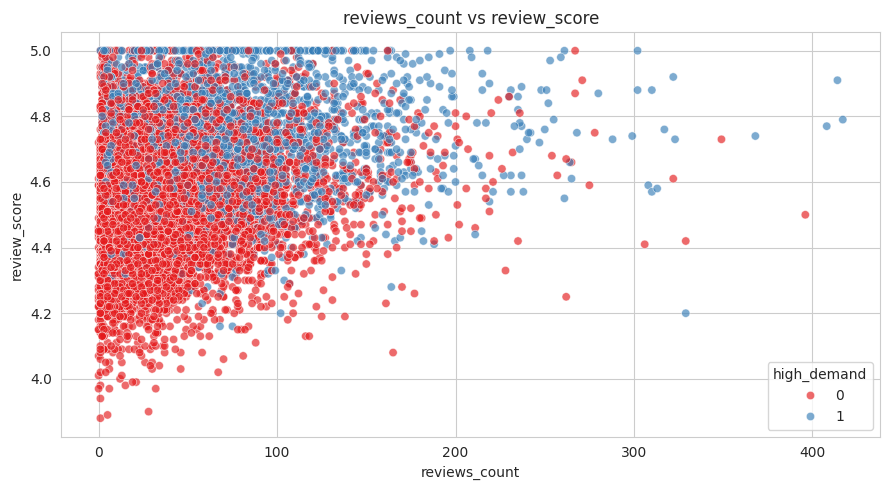

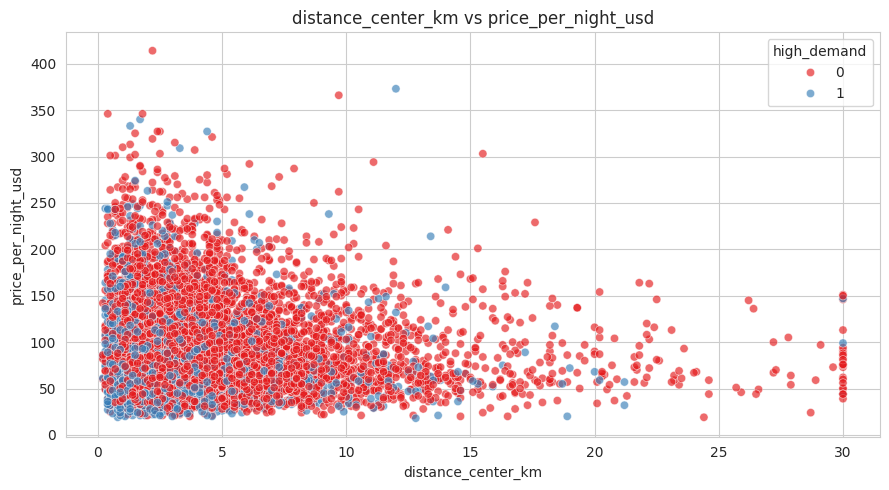

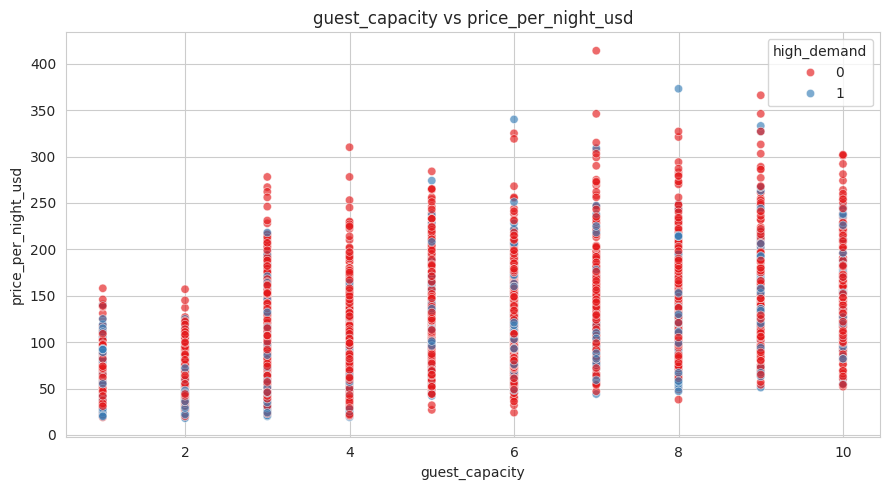

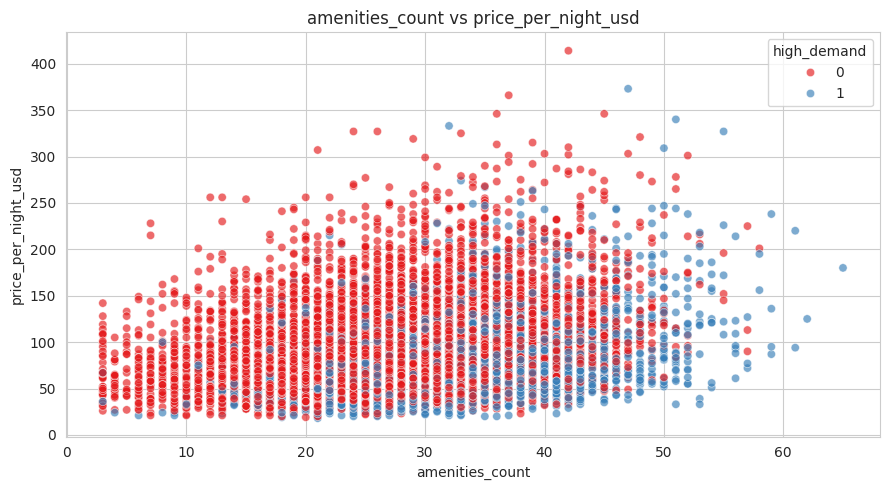

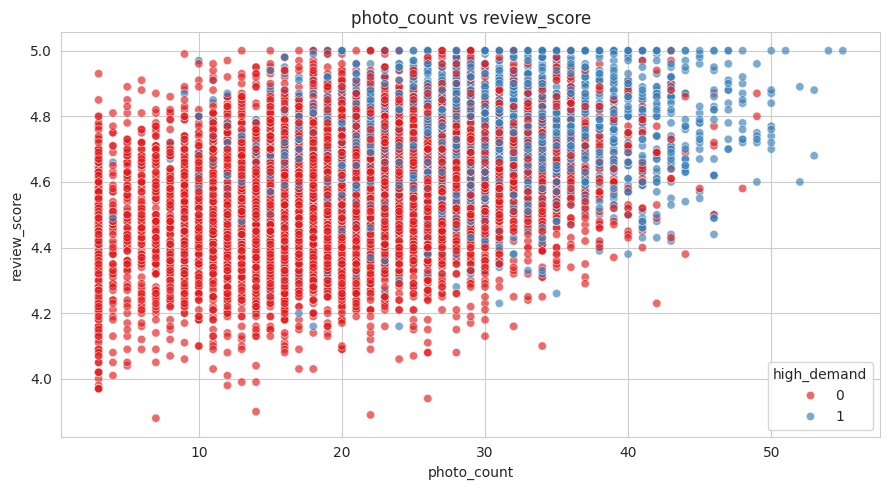

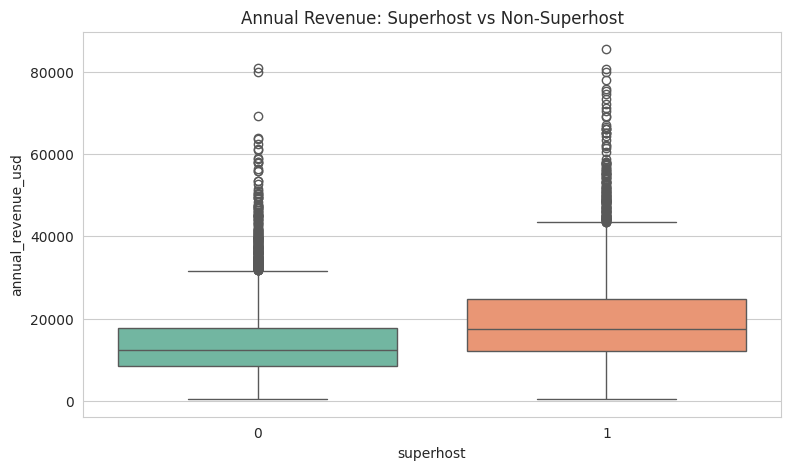

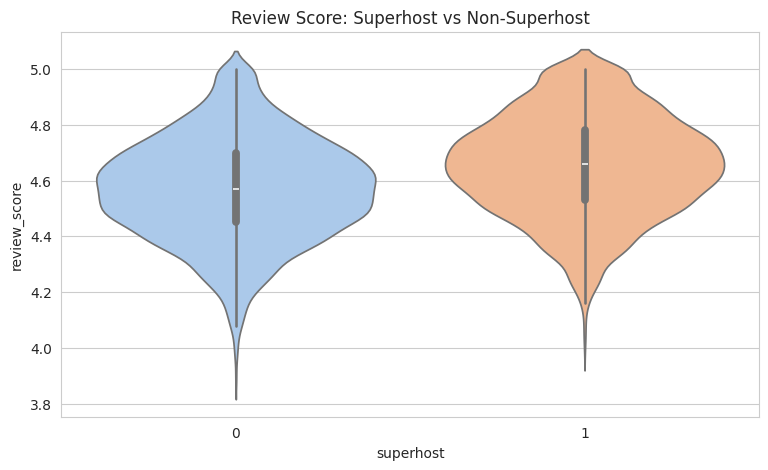

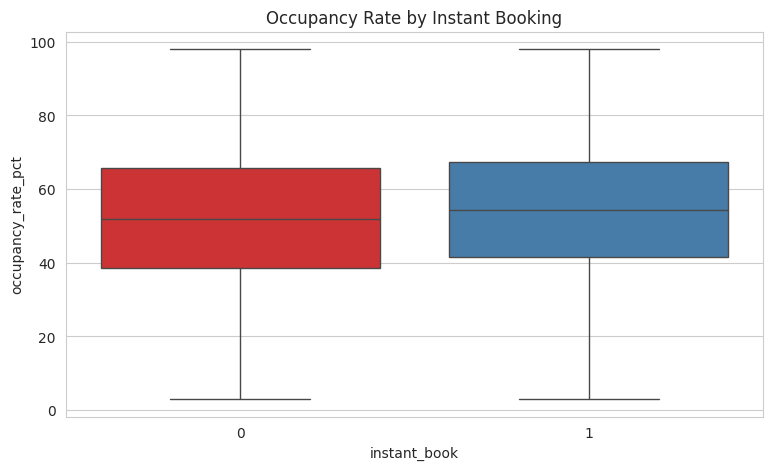

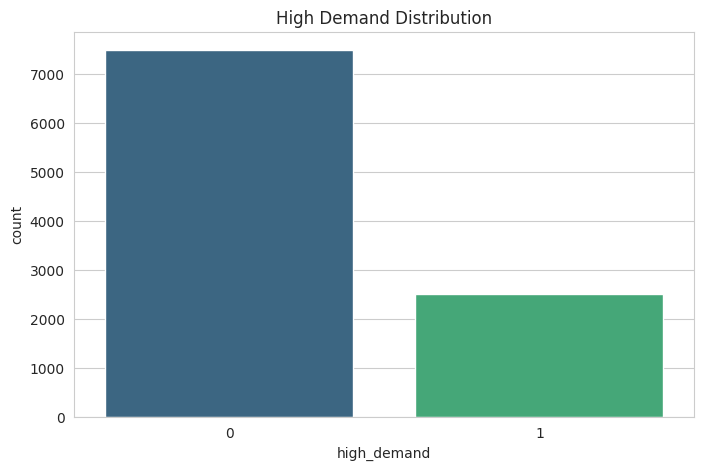

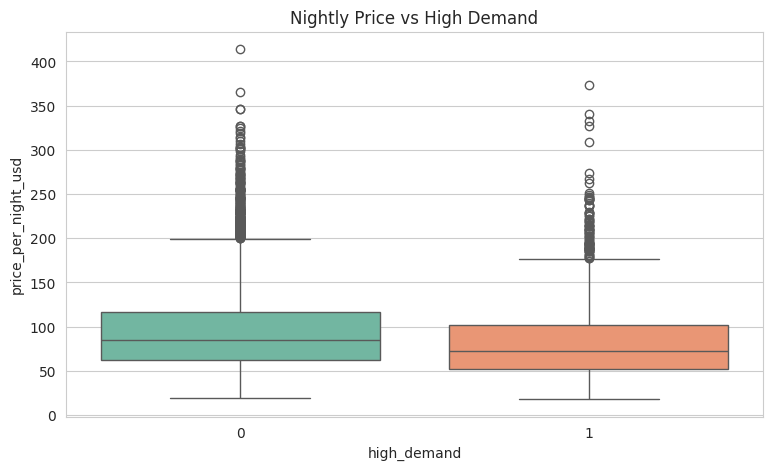

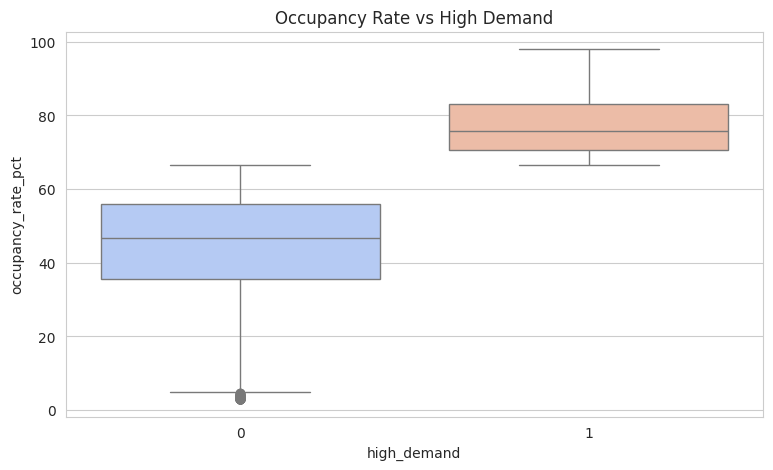

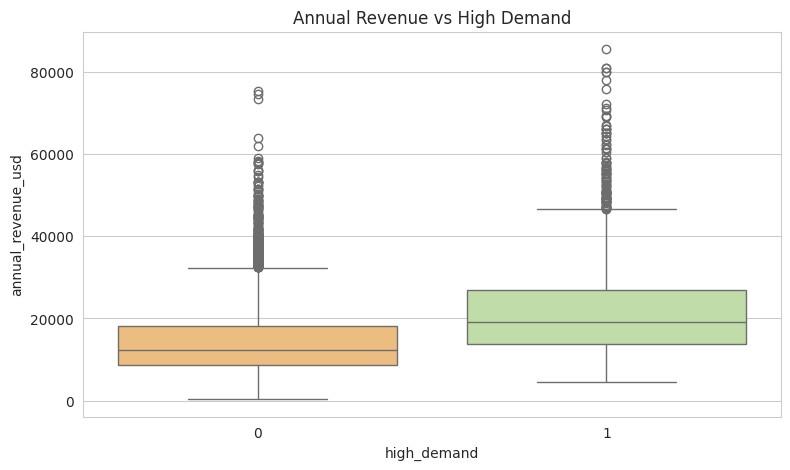

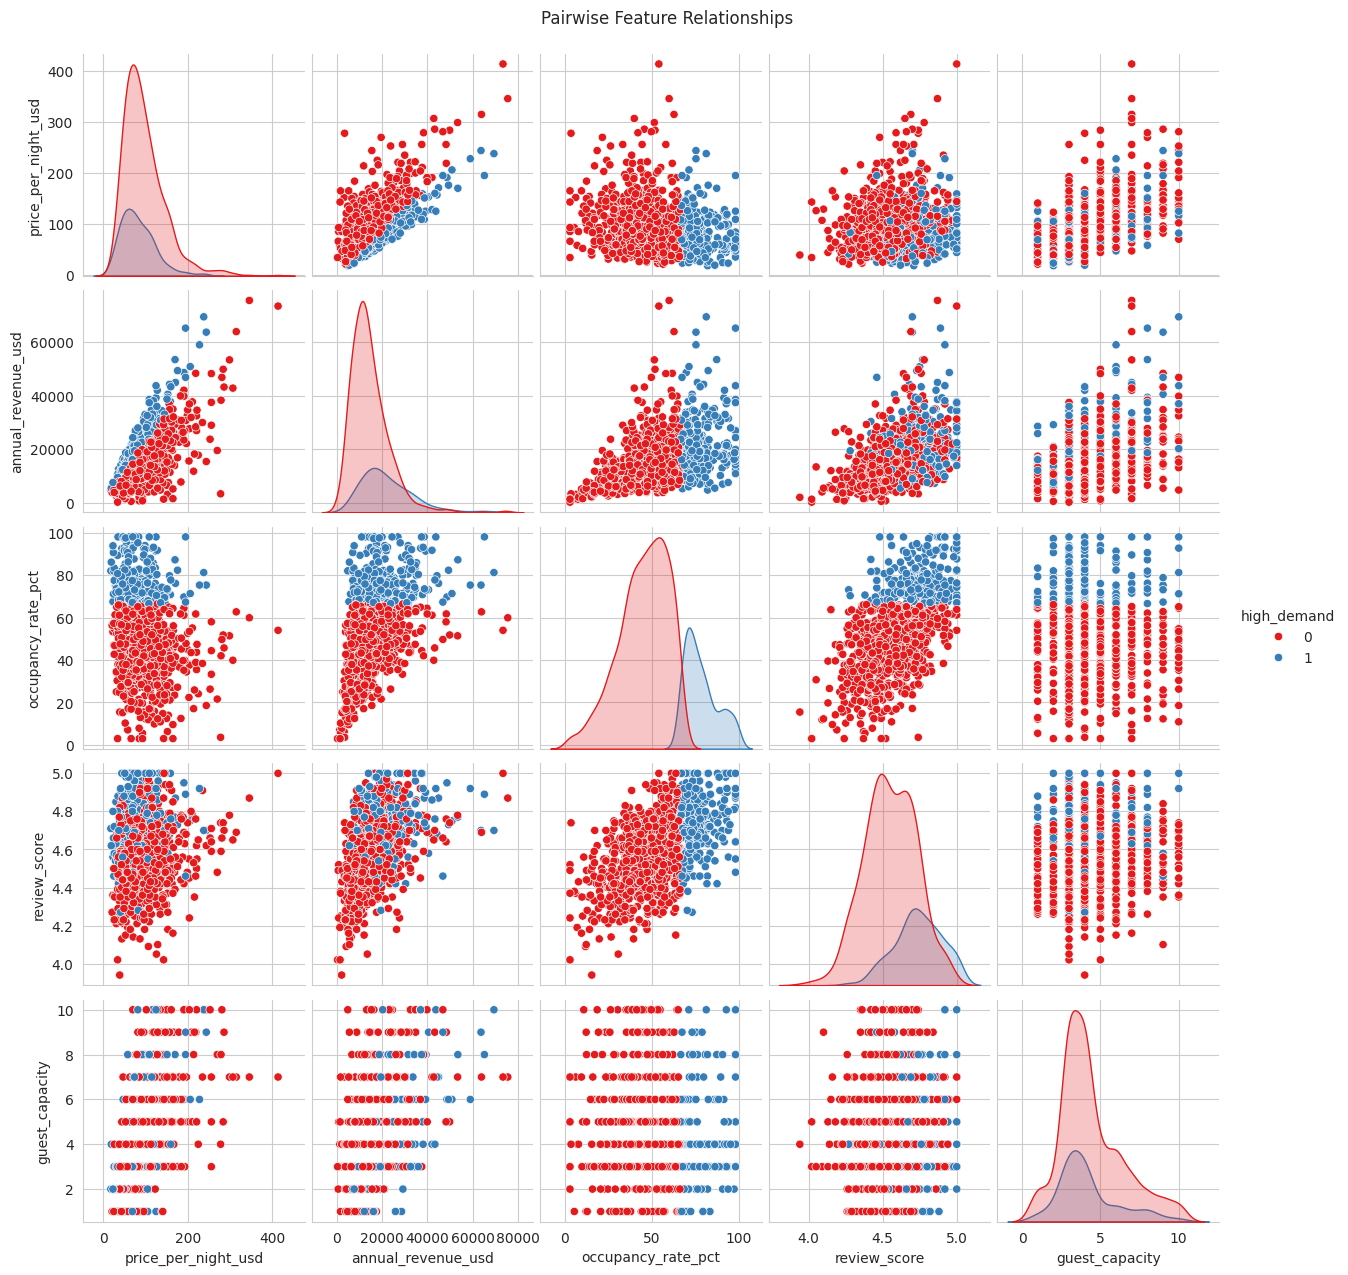

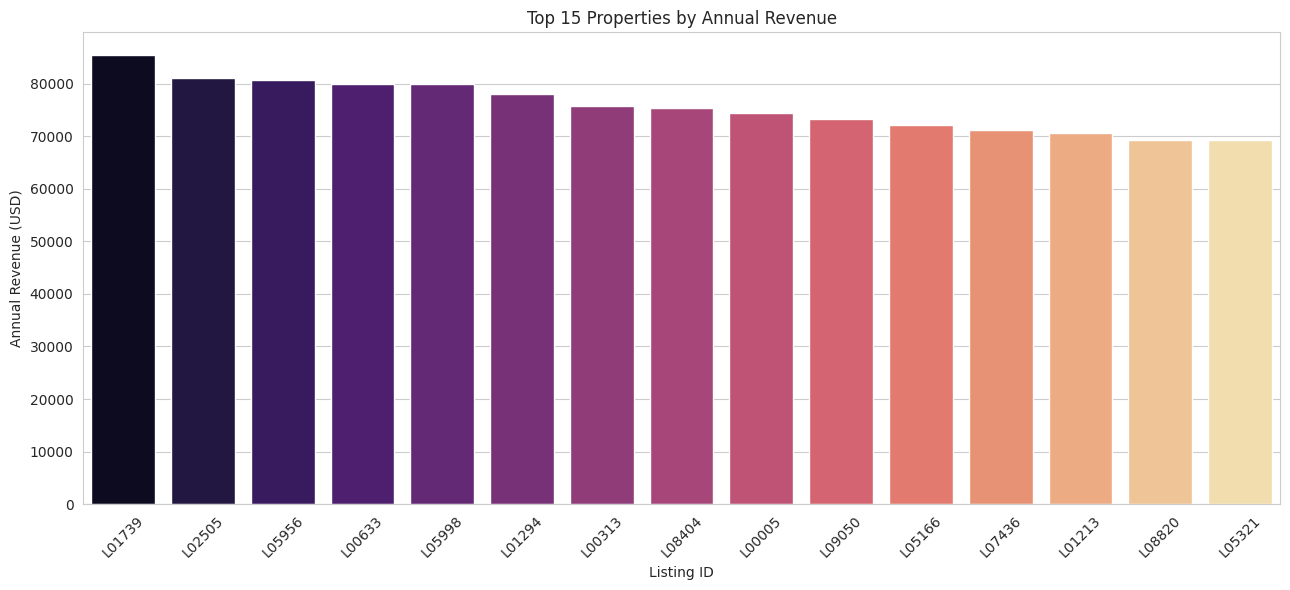

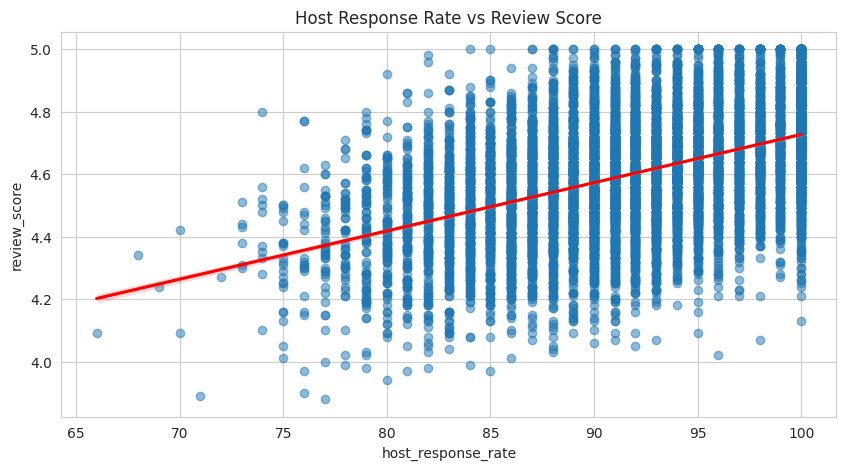

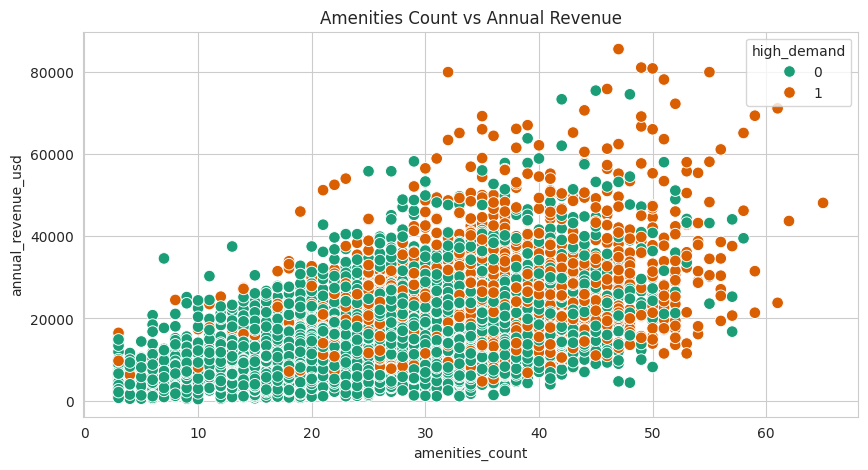


FINAL EDA SUMMARY
Total Listings: 10000
Total Features: 21
Total Cities: 12
Total Property Types: 4
Average Nightly Price: $ 91.67
Average Annual Revenue: $ 16125.83

High Demand Distribution:
high_demand
0    7496
1    2504
Name: count, dtype: int64

EDA and Visualization Completed Successfully!


In [13]:
# Plot styling
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

# 2. Load Dataset
# df = pd.read_csv('/kaggle/input/dataset-name/file.csv')

# If df is already loaded, skip the above line.

# 3. Basic Dataset Information
print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("\nDataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all').T)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


# 4. Handle Missing Values (Visualization preparation)
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# 5. Missing Values Visualization
plt.figure(figsize=(14, 6))
sns.heatmap(df.isnull(), cmap='magma', cbar=False, yticklabels=False)
plt.title("Missing Values Overview", fontsize=16)
plt.show()

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    plt.figure(figsize=(12, 5))
    sns.barplot(x=missing.index, y=missing.values, palette='rocket')
    plt.title("Missing Values by Column")
    plt.xticks(rotation=45, ha='right')
    plt.ylabel("Missing Count")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


# 6. Numerical Features Distribution
selected_num = [
    'bedrooms', 'bathrooms', 'guest_capacity',
    'distance_center_km', 'price_per_night_usd',
    'cleaning_fee_usd', 'host_response_rate',
    'host_years', 'photo_count', 'amenities_count',
    'min_nights', 'review_score', 'reviews_count',
    'occupancy_rate_pct', 'annual_revenue_usd'
]

selected_num = [col for col in selected_num if col in df.columns]

for col in selected_num:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.histplot(
        df[col].dropna(),
        kde=True,
        color='#3498DB',
        ax=axes[0]
    )
    axes[0].set_title(f'{col} Distribution')

    sns.boxplot(
        x=df[col],
        color='#E67E22',
        ax=axes[1]
    )
    axes[1].set_title(f'{col} Boxplot')

    plt.tight_layout()
    plt.show()


# 7. Categorical Features Analysis
selected_cat = [
    'city', 'property_type', 'superhost',
    'instant_book', 'high_demand'
]

selected_cat = [col for col in selected_cat if col in df.columns]

for col in selected_cat:
    plt.figure(figsize=(12, 5))

    order = df[col].value_counts().head(15).index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        palette='Set2'
    )

    plt.title(f'{col} Count Distribution', fontsize=15)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


# 8. Property Type Distribution
if 'property_type' in df.columns:
    plt.figure(figsize=(10, 7))

    property_counts = df['property_type'].value_counts()

    plt.pie(
        property_counts,
        labels=property_counts.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=sns.color_palette('pastel', len(property_counts)),
        wedgeprops={'edgecolor': 'white'}
    )

    plt.title("Property Type Distribution")
    plt.show()


# 9. City-wise Property Listings
if 'city' in df.columns:
    plt.figure(figsize=(12, 6))

    city_counts = df['city'].value_counts().head(15)

    sns.barplot(
        x=city_counts.values,
        y=city_counts.index,
        palette='viridis'
    )

    plt.title("Top 15 Cities by Property Listings")
    plt.xlabel("Number of Listings")
    plt.ylabel("City")
    plt.show()


# 10. Price Analysis
if 'price_per_night_usd' in df.columns:

    plt.figure(figsize=(12, 5))

    sns.histplot(
        df['price_per_night_usd'].dropna(),
        bins=40,
        kde=True,
        color='#9B59B6'
    )

    plt.title("Nightly Rental Price Distribution")
    plt.xlabel("Price per Night (USD)")
    plt.ylabel("Frequency")
    plt.show()

    # Price by property type
    if 'property_type' in df.columns:
        plt.figure(figsize=(13, 6))

        sns.boxplot(
            data=df,
            x='property_type',
            y='price_per_night_usd',
            palette='Set3'
        )

        plt.title("Nightly Price by Property Type")
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

    # Price by city
    if 'city' in df.columns:
        city_order = df.groupby('city')['price_per_night_usd'].median().sort_values(ascending=False).head(15).index

        plt.figure(figsize=(13, 6))

        sns.barplot(
            data=df[df['city'].isin(city_order)],
            x='city',
            y='price_per_night_usd',
            estimator='median',
            errorbar=None,
            palette='coolwarm',
            order=city_order
        )

        plt.title("Median Nightly Price by City")
        plt.xticks(rotation=45, ha='right')
        plt.ylabel("Median Price (USD)")
        plt.tight_layout()
        plt.show()


# 11. Correlation Heatmap
if len(numeric_cols) > 1:

    plt.figure(figsize=(16, 12))

    correlation = df[numeric_cols].corr()

    sns.heatmap(
        correlation,
        annot=True,
        fmt='.2f',
        cmap='RdYlBu_r',
        linewidths=0.5,
        center=0
    )

    plt.title("Numerical Features Correlation Heatmap", fontsize=16)
    plt.tight_layout()
    plt.show()


# 12. Scatter Plots - Important Relationships
scatter_pairs = [
    ('price_per_night_usd', 'annual_revenue_usd'),
    ('price_per_night_usd', 'occupancy_rate_pct'),
    ('review_score', 'annual_revenue_usd'),
    ('reviews_count', 'review_score'),
    ('distance_center_km', 'price_per_night_usd'),
    ('guest_capacity', 'price_per_night_usd'),
    ('amenities_count', 'price_per_night_usd'),
    ('photo_count', 'review_score')
]

for x, y in scatter_pairs:
    if x in df.columns and y in df.columns:

        plt.figure(figsize=(9, 5))

        sns.scatterplot(
            data=df,
            x=x,
            y=y,
            hue='high_demand' if 'high_demand' in df.columns else None,
            palette='Set1',
            alpha=0.65
        )

        plt.title(f'{x} vs {y}')
        plt.tight_layout()
        plt.show()


# 13. Superhost Analysis
if 'superhost' in df.columns:

    if 'annual_revenue_usd' in df.columns:
        plt.figure(figsize=(9, 5))

        sns.boxplot(
            data=df,
            x='superhost',
            y='annual_revenue_usd',
            palette='Set2'
        )

        plt.title("Annual Revenue: Superhost vs Non-Superhost")
        plt.show()

    if 'review_score' in df.columns:
        plt.figure(figsize=(9, 5))

        sns.violinplot(
            data=df,
            x='superhost',
            y='review_score',
            palette='pastel'
        )

        plt.title("Review Score: Superhost vs Non-Superhost")
        plt.show()


# 14. Instant Booking Analysis
if 'instant_book' in df.columns and 'occupancy_rate_pct' in df.columns:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x='instant_book',
        y='occupancy_rate_pct',
        palette='Set1'
    )

    plt.title("Occupancy Rate by Instant Booking")
    plt.show()


# 15. High Demand Analysis
if 'high_demand' in df.columns:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x='high_demand',
        palette='viridis'
    )

    plt.title("High Demand Distribution")
    plt.show()

    # High demand vs nightly price
    if 'price_per_night_usd' in df.columns:

        plt.figure(figsize=(9, 5))

        sns.boxplot(
            data=df,
            x='high_demand',
            y='price_per_night_usd',
            palette='Set2'
        )

        plt.title("Nightly Price vs High Demand")
        plt.show()

    # High demand vs occupancy
    if 'occupancy_rate_pct' in df.columns:

        plt.figure(figsize=(9, 5))

        sns.boxplot(
            data=df,
            x='high_demand',
            y='occupancy_rate_pct',
            palette='coolwarm'
        )

        plt.title("Occupancy Rate vs High Demand")
        plt.show()

    # High demand vs revenue
    if 'annual_revenue_usd' in df.columns:

        plt.figure(figsize=(9, 5))

        sns.boxplot(
            data=df,
            x='high_demand',
            y='annual_revenue_usd',
            palette='Spectral'
        )

        plt.title("Annual Revenue vs High Demand")
        plt.show()


# 16. Pairplot - Selected Features
pair_cols = [
    'price_per_night_usd',
    'annual_revenue_usd',
    'occupancy_rate_pct',
    'review_score',
    'guest_capacity'
]

pair_cols = [col for col in pair_cols if col in df.columns]

if len(pair_cols) >= 2:
    pair_data = df[pair_cols + (['high_demand'] if 'high_demand' in df.columns else [])].dropna()

    # Sample for faster execution
    if len(pair_data) > 1000:
        pair_data = pair_data.sample(1000, random_state=42)

    sns.pairplot(
        pair_data,
        hue='high_demand' if 'high_demand' in df.columns else None,
        palette='Set1',
        diag_kind='kde'
    )

    plt.suptitle("Pairwise Feature Relationships", y=1.02)
    plt.show()


# 17. Top 15 Properties by Annual Revenue
if 'annual_revenue_usd' in df.columns and 'listing_id' in df.columns:

    top_properties = df.nlargest(15, 'annual_revenue_usd')

    plt.figure(figsize=(13, 6))

    sns.barplot(
        data=top_properties,
        x='listing_id',
        y='annual_revenue_usd',
        palette='magma'
    )

    plt.title("Top 15 Properties by Annual Revenue")
    plt.xlabel("Listing ID")
    plt.ylabel("Annual Revenue (USD)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# 18. Host Response Rate Analysis
if 'host_response_rate' in df.columns and 'review_score' in df.columns:

    plt.figure(figsize=(10, 5))

    sns.regplot(
        data=df,
        x='host_response_rate',
        y='review_score',
        scatter_kws={'alpha': 0.5},
        line_kws={'color': 'red'}
    )

    plt.title("Host Response Rate vs Review Score")
    plt.show()


# 19. Amenities vs Revenue
if 'amenities_count' in df.columns and 'annual_revenue_usd' in df.columns:

    plt.figure(figsize=(10, 5))

    sns.scatterplot(
        data=df,
        x='amenities_count',
        y='annual_revenue_usd',
        hue='high_demand' if 'high_demand' in df.columns else None,
        palette='Dark2',
        s=70
    )

    plt.title("Amenities Count vs Annual Revenue")
    plt.show()


# 20. Final Dataset Summary
print("\n" + "=" * 60)
print("FINAL EDA SUMMARY")
print("=" * 60)

print("Total Listings:", len(df))
print("Total Features:", df.shape[1])

if 'city' in df.columns:
    print("Total Cities:", df['city'].nunique())

if 'property_type' in df.columns:
    print("Total Property Types:", df['property_type'].nunique())

if 'price_per_night_usd' in df.columns:
    print("Average Nightly Price: $", round(df['price_per_night_usd'].mean(), 2))

if 'annual_revenue_usd' in df.columns:
    print("Average Annual Revenue: $", round(df['annual_revenue_usd'].mean(), 2))

if 'high_demand' in df.columns:
    print("\nHigh Demand Distribution:")
    print(df['high_demand'].value_counts())

print("\nEDA and Visualization Completed Successfully!")


## Feature engineering

Dataset Shape: (10000, 21)

First 5 Records:


,listing_id,city,property_type,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,...,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
0,L00001,Mexico City,Entire home,2,1.5,5,7.1,52.0,17.0,1,...,6.9,27,23,0,30,4.59,3,61.3,11500.0,0
1,L00002,Paris,Entire home,1,1.0,3,4.6,147.0,52.0,0,...,1.4,13,20,1,7,4.61,7,23.7,11300.0,0
2,L00003,New York,Entire home,2,2.0,5,1.6,131.0,36.0,0,...,5.1,18,35,0,30,4.64,6,45.8,21700.0,0
3,L00004,Tokyo,Entire home,2,1.5,5,5.7,164.0,68.0,0,...,3.6,36,43,0,2,4.71,20,42.6,25300.0,0
4,L00005,Berlin,Entire home,3,2.0,8,4.6,321.0,32.0,1,...,5.6,27,48,1,5,4.98,28,65.1,74500.0,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           10000 non-null  object 
 1   city                 10000 non-null  object 
 2   property_type        10000 non-null  object 
 3   bedrooms             10000 non-null  int64  
 4   bathrooms            10000 non-null  float64
 5   guest_capacity       10000 non-null  int64  
 6   distance_center_km   10000 non-null  float64
 7   price_per_night_usd  10000 non-null  float64
 8   cleaning_fee_usd     10000 non-null  float64
 9   superhost            10000 non-null  int64  
 10  host_response_rate   10000 non-null  float64
 11  host_years           10000 non-null  float64
 12  photo_count          10000 non-null  int64  
 13  amenities_count      10000 non-null  int64  
 14  instant_book         10000 non-null  int64  
 15  min_nights     

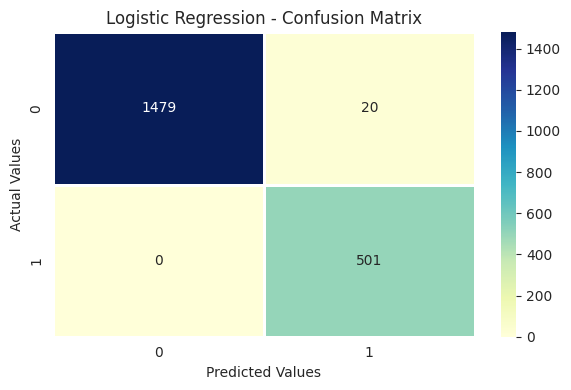


TRAINING: Decision Tree

Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %
ROC AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1499
           1       1.00      1.00      1.00       501

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



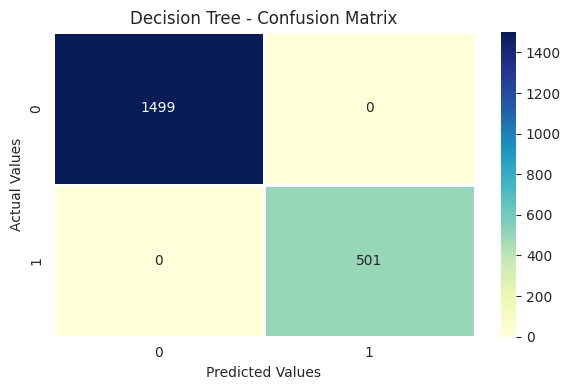


TRAINING: Random Forest

Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %
ROC AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1499
           1       1.00      1.00      1.00       501

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



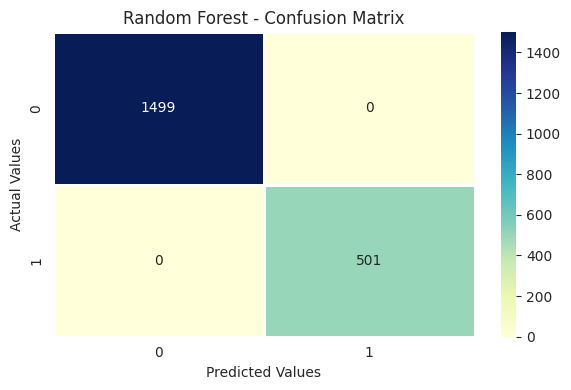


TRAINING: KNN

Accuracy: 90.6 %
Precision: 86.14 %
Recall: 74.45 %
F1 Score: 79.87 %
ROC AUC: 0.9453

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.96      0.94      1499
           1       0.86      0.74      0.80       501

    accuracy                           0.91      2000
   macro avg       0.89      0.85      0.87      2000
weighted avg       0.90      0.91      0.90      2000



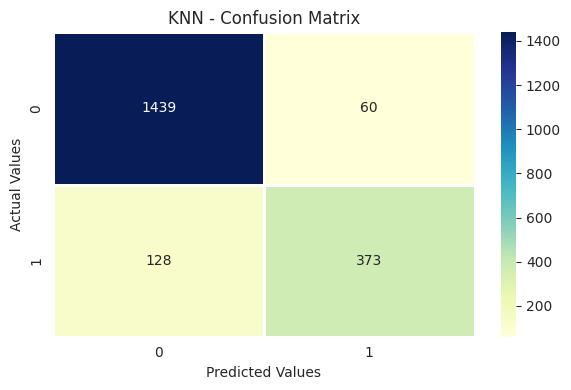


TRAINING: SVM

Accuracy: 97.3 %
Precision: 90.71 %
Recall: 99.4 %
F1 Score: 94.86 %
ROC AUC: 0.9987

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98      1499
           1       0.91      0.99      0.95       501

    accuracy                           0.97      2000
   macro avg       0.95      0.98      0.97      2000
weighted avg       0.98      0.97      0.97      2000



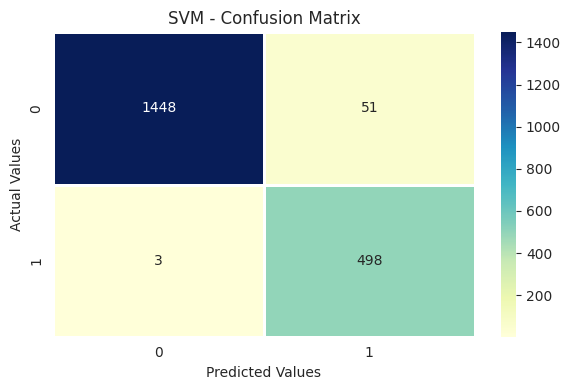


TRAINING: Gradient Boosting

Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %
ROC AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1499
           1       1.00      1.00      1.00       501

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



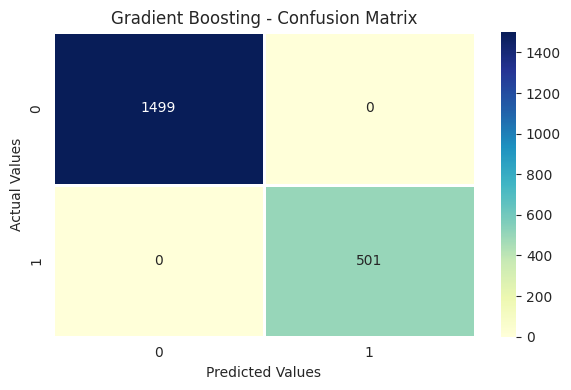


TRAINING: AdaBoost

Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %
ROC AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1499
           1       1.00      1.00      1.00       501

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



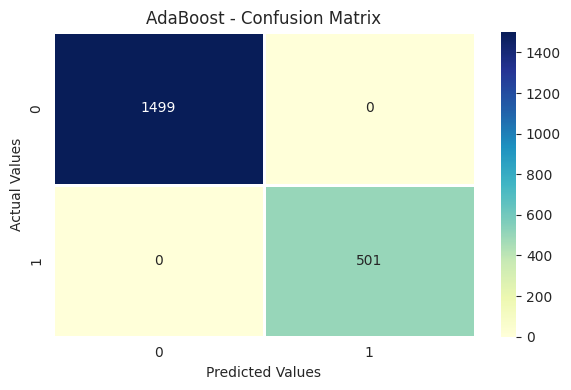


TRAINING: Extra Trees

Accuracy: 98.75 %
Precision: 96.67 %
Recall: 98.4 %
F1 Score: 97.53 %
ROC AUC: 0.9991

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1499
           1       0.97      0.98      0.98       501

    accuracy                           0.99      2000
   macro avg       0.98      0.99      0.98      2000
weighted avg       0.99      0.99      0.99      2000



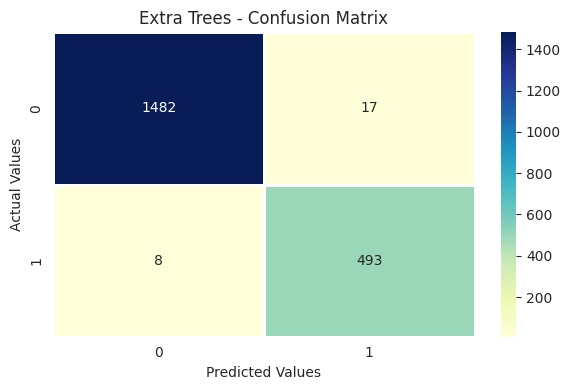


TRAINING: Gaussian Naive Bayes

Accuracy: 93.1 %
Precision: 83.06 %
Recall: 91.02 %
F1 Score: 86.86 %
ROC AUC: 0.9781

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.94      0.95      1499
           1       0.83      0.91      0.87       501

    accuracy                           0.93      2000
   macro avg       0.90      0.92      0.91      2000
weighted avg       0.93      0.93      0.93      2000



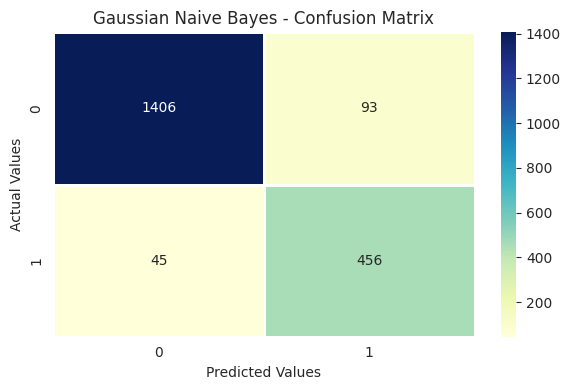


TRAINING: XGBoost

Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %
ROC AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1499
           1       1.00      1.00      1.00       501

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



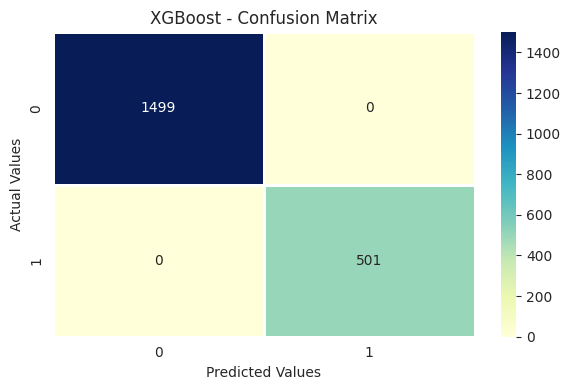


TRAINING: LightGBM

Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %
ROC AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1499
           1       1.00      1.00      1.00       501

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



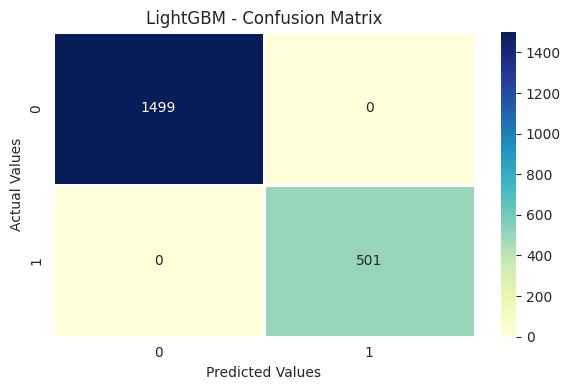


TRAINING: CatBoost

Accuracy: 100.0 %
Precision: 100.0 %
Recall: 100.0 %
F1 Score: 100.0 %
ROC AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1499
           1       1.00      1.00      1.00       501

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



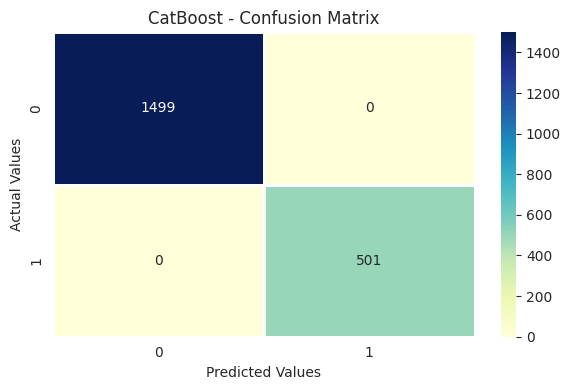


MACHINE LEARNING MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Decision Tree,100.00,100.00,100.00,100.00,1.00
1,Random Forest,100.00,100.00,100.00,100.00,1.00
2,AdaBoost,100.00,100.00,100.00,100.00,1.00
3,Gradient Boosting,100.00,100.00,100.00,100.00,1.00
4,LightGBM,100.00,100.00,100.00,100.00,1.00
5,CatBoost,100.00,100.00,100.00,100.00,1.00
6,XGBoost,100.00,100.00,100.00,100.00,1.00
7,Logistic Regression,99.00,96.16,100.00,98.04,1.00
8,Extra Trees,98.75,96.67,98.40,97.53,1.00
9,SVM,97.30,90.71,99.40,94.86,1.00


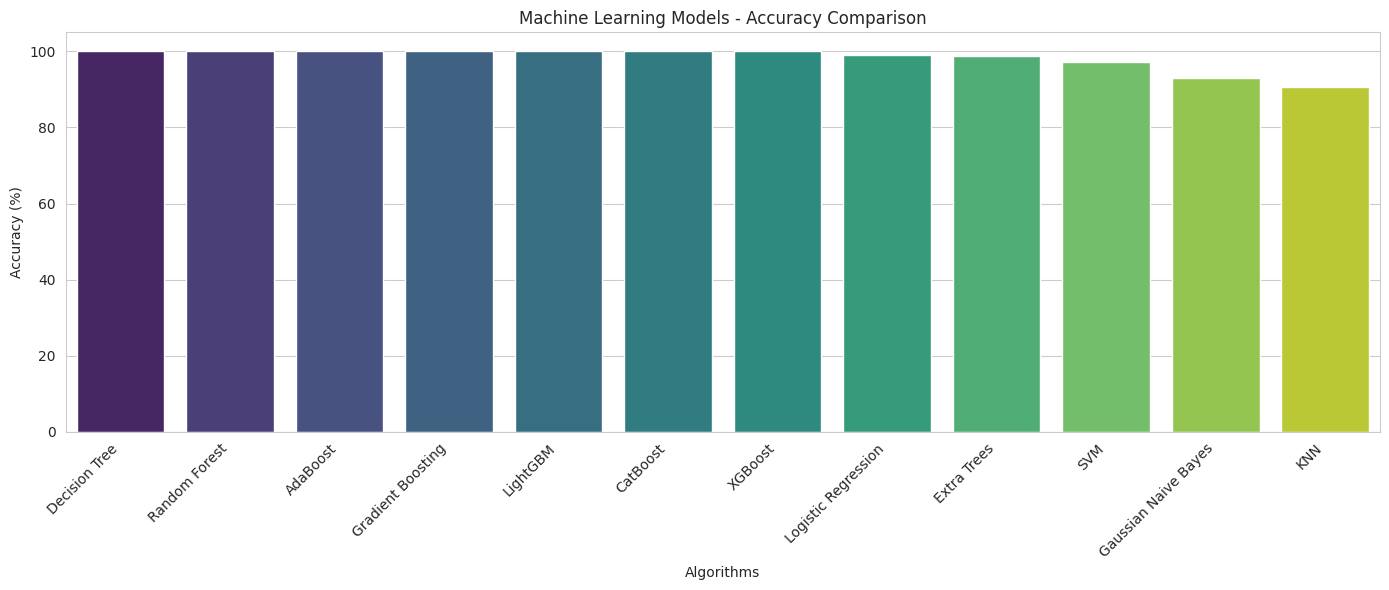

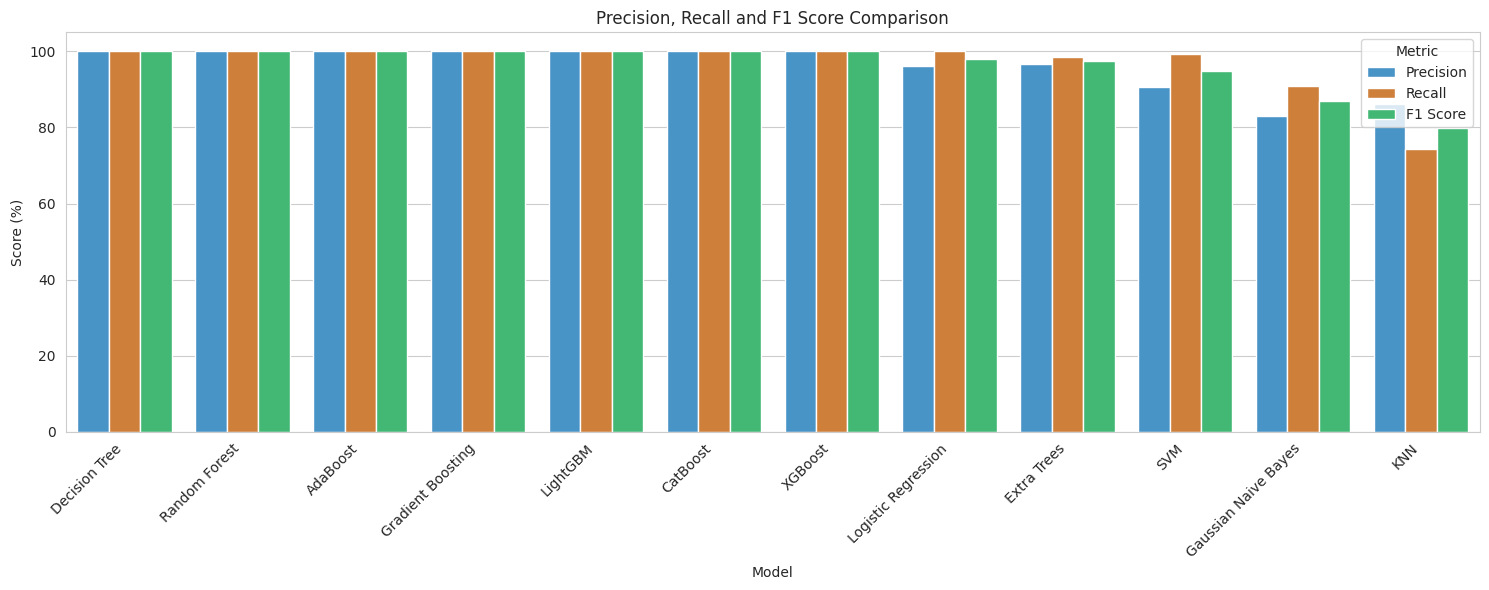

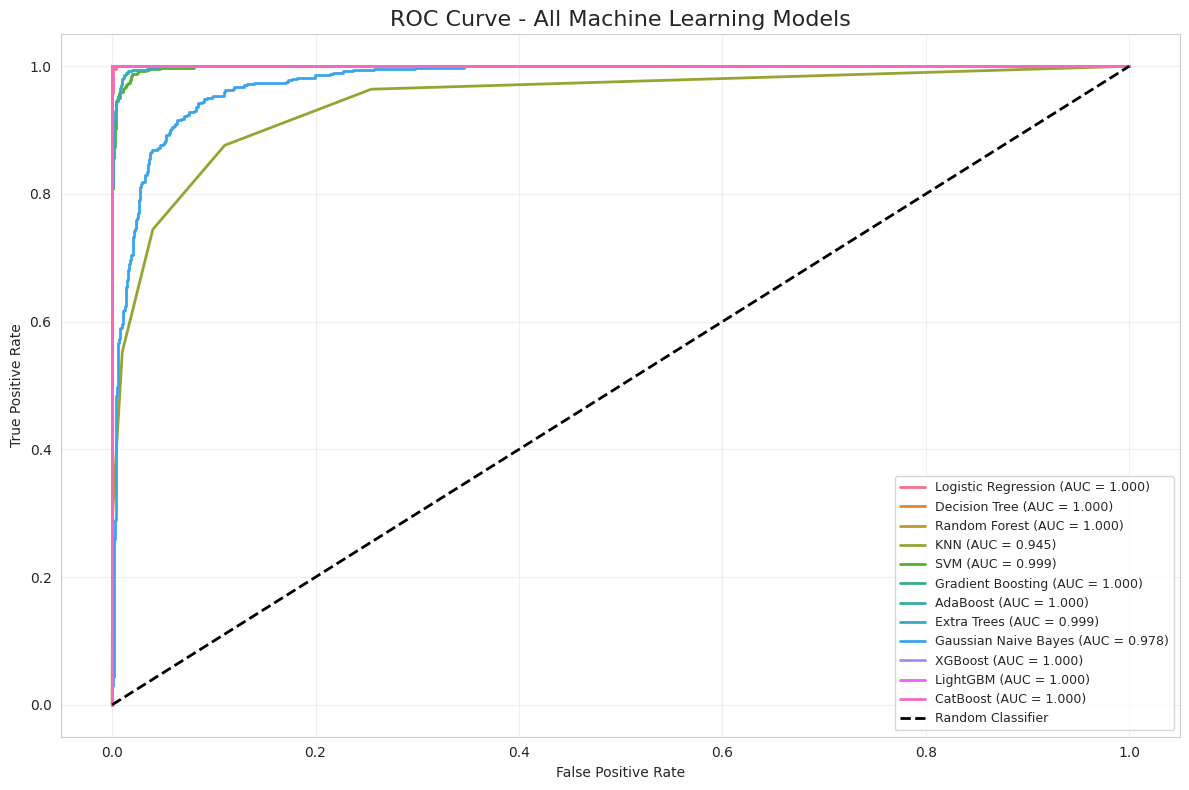

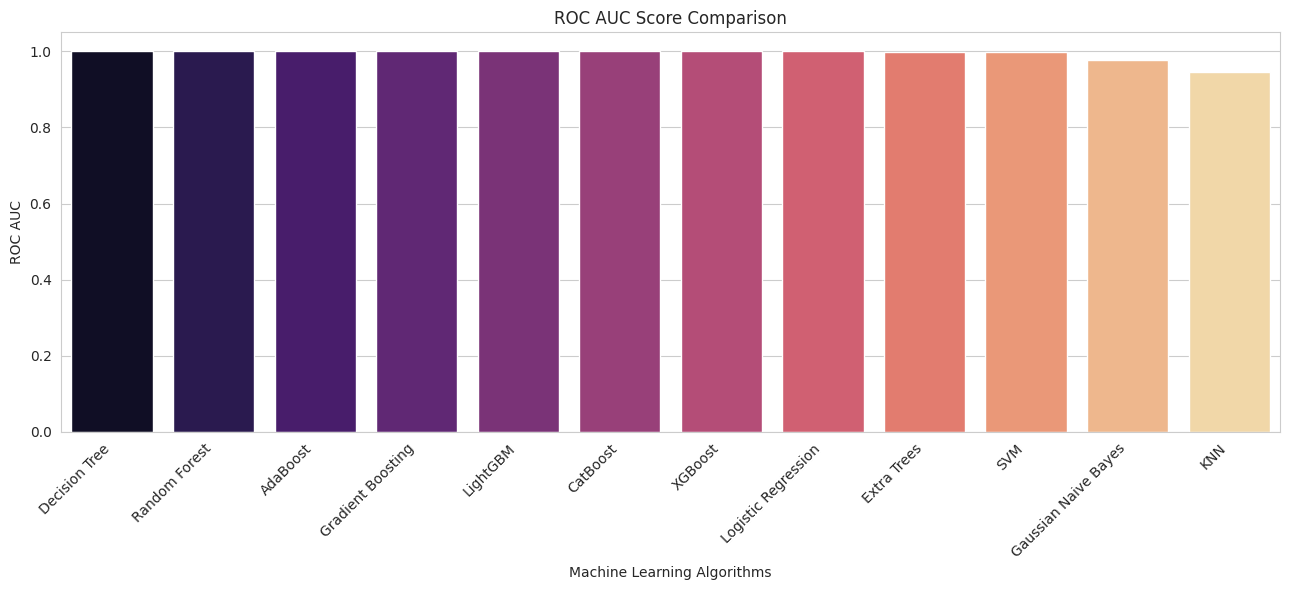


BEST MACHINE LEARNING MODEL
Best Model: Decision Tree
Accuracy: 100.0 %
ROC AUC: 1.0


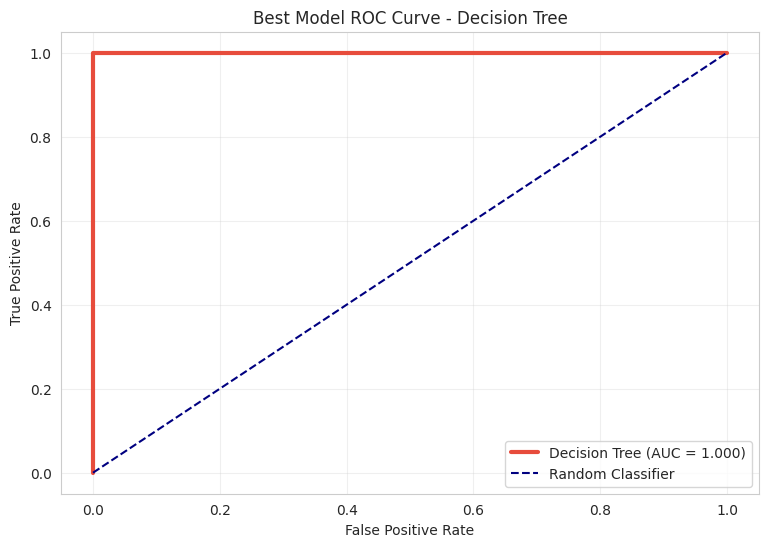


Random Forest Feature Importance:


,Feature,Importance
17,occupancy_rate_pct,0.711735
11,photo_count,0.063222
15,review_score,0.038873
9,host_response_rate,0.038377
18,annual_revenue_usd,0.029096
16,reviews_count,0.026284
6,price_per_night_usd,0.024363
12,amenities_count,0.016825
8,superhost,0.014732
7,cleaning_fee_usd,0.011213


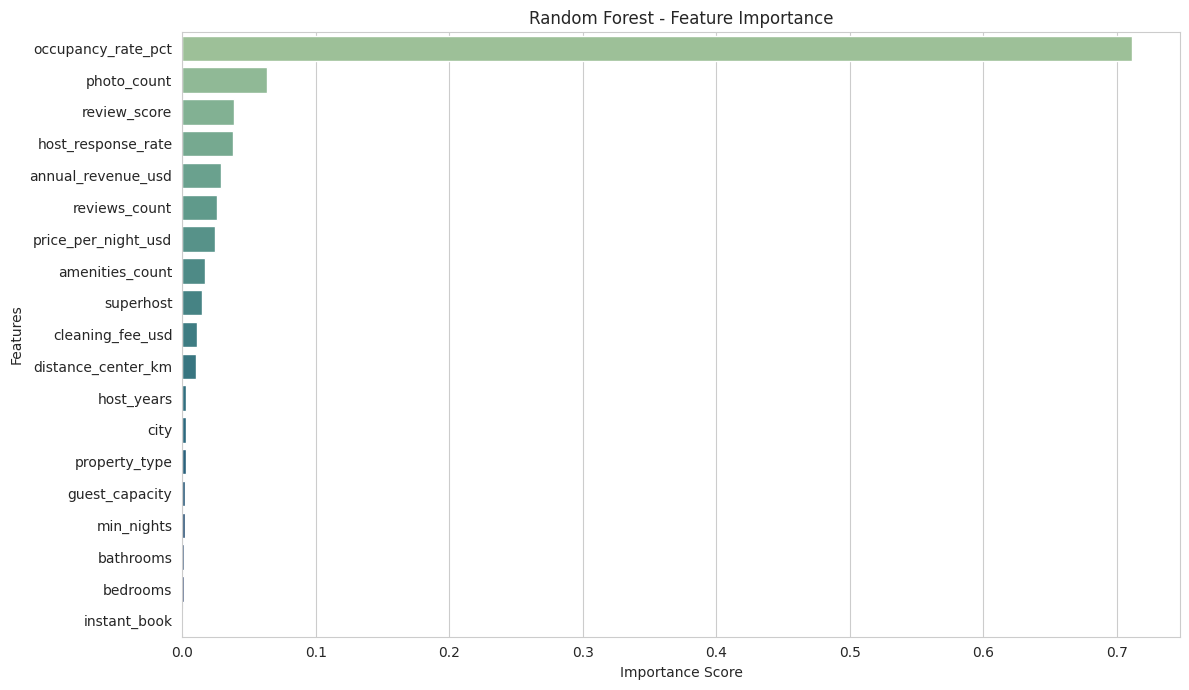


MACHINE LEARNING PIPELINE COMPLETED SUCCESSFULLY

Total Models Trained: 12

Best Performing Model: Decision Tree

Final Model Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Decision Tree,100.00,100.00,100.00,100.00,1.00
1,Random Forest,100.00,100.00,100.00,100.00,1.00
2,AdaBoost,100.00,100.00,100.00,100.00,1.00
3,Gradient Boosting,100.00,100.00,100.00,100.00,1.00
4,LightGBM,100.00,100.00,100.00,100.00,1.00
5,CatBoost,100.00,100.00,100.00,100.00,1.00
6,XGBoost,100.00,100.00,100.00,100.00,1.00
7,Logistic Regression,99.00,96.16,100.00,98.04,1.00
8,Extra Trees,98.75,96.67,98.40,97.53,1.00
9,SVM,97.30,90.71,99.40,94.86,1.00



Target Classes: ['0' '1']

Train Samples: 8000
Test Samples: 2000


In [14]:

# ================================================================
# AIRBNB PROPERTY RENTAL - MACHINE LEARNING CLASSIFICATION
# Train Test Split | Label Encoding | 12 ML Algorithms | ROC Curve
# ================================================================


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    ExtraTreesClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# ================================================================
# 2. LOAD DATASET
# ================================================================

# Uncomment if dataset is not already loaded

# df = pd.read_csv('/kaggle/input/dataset-name/airbnb.csv')

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
print(df.info())

# ================================================================
# 3. DATA CLEANING
# ================================================================

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows where target is missing
df = df.dropna(subset=['high_demand'])

# Remove ID column because it is not a useful predictive feature
if 'listing_id' in df.columns:
    df = df.drop(columns=['listing_id'])

# Remove infinite values
df = df.replace([np.inf, -np.inf], np.nan)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCleaned Dataset Shape:", df.shape)

# ================================================================
# 4. DEFINE TARGET AND FEATURES
# ================================================================

target = 'high_demand'

X = df.drop(columns=[target])
y = df[target]

print("\nTarget Variable:", target)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

# IMPORTANT:
# If high_demand was calculated using occupancy_rate_pct or
# annual_revenue_usd, remove those columns to avoid data leakage.
#
# Example:
# X = X.drop(columns=[
#     'occupancy_rate_pct',
#     'annual_revenue_usd'
# ], errors='ignore')

# ================================================================
# 5. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ================================================================

numeric_features = X.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

# ================================================================
# 6. TRAIN TEST SPLITTING
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

# ================================================================
# 7. HANDLE MISSING VALUES
# ================================================================

# Numerical columns: Median imputation
if numeric_features:
    num_imputer = SimpleImputer(strategy='median')

    X_train[numeric_features] = num_imputer.fit_transform(
        X_train[numeric_features]
    )

    X_test[numeric_features] = num_imputer.transform(
        X_test[numeric_features]
    )

# Categorical columns: Most frequent imputation
if categorical_features:
    cat_imputer = SimpleImputer(strategy='most_frequent')

    X_train[categorical_features] = cat_imputer.fit_transform(
        X_train[categorical_features]
    )

    X_test[categorical_features] = cat_imputer.transform(
        X_test[categorical_features]
    )

# ================================================================
# 8. LABEL ENCODING
# ================================================================

# Encode categorical feature columns.
# Fit encoders ONLY on training data.
# Unknown test categories receive -1.

label_encoders = {}

for col in categorical_features:

    le = LabelEncoder()

    X_train[col] = le.fit_transform(
        X_train[col].astype(str)
    )

    mapping = {
        label: index
        for index, label in enumerate(le.classes_)
    }

    X_test[col] = (
        X_test[col]
        .astype(str)
        .map(mapping)
        .fillna(-1)
        .astype(int)
    )

    label_encoders[col] = le

print("\nLabel Encoding Completed!")

for col, le in label_encoders.items():
    print(f"\n{col}:")
    print(dict(zip(le.classes_, le.transform(le.classes_))))

# ================================================================
# 9. TARGET LABEL ENCODING
# ================================================================

target_encoder = LabelEncoder()

y_train = target_encoder.fit_transform(y_train.astype(str))

y_test = np.array([
    target_encoder.transform([str(value)])[0]
    for value in y_test
])

print("\nTarget Classes:")
print(target_encoder.classes_)

print("\nEncoded Training Target:")
print(np.unique(y_train))

# ROC code below is for binary classification.
if len(target_encoder.classes_) != 2:
    raise ValueError(
        "This ROC implementation requires exactly 2 target classes."
    )

# ================================================================
# 10. FEATURE SCALING
# ================================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed!")

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

# ================================================================
# 11. DEFINE MACHINE LEARNING ALGORITHMS
# ================================================================

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'SVM': SVC(
        kernel='rbf',
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'Gaussian Naive Bayes': GaussianNB()
}

# ================================================================
# 12. ADD XGBOOST
# ================================================================

try:
    from xgboost import XGBClassifier

    models['XGBoost'] = XGBClassifier(
        n_estimators=150,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("\nXGBoost is not installed. Skipping XGBoost.")

# ================================================================
# 13. ADD LIGHTGBM
# ================================================================

try:
    from lightgbm import LGBMClassifier

    models['LightGBM'] = LGBMClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=7,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("\nLightGBM is not installed. Skipping LightGBM.")

# ================================================================
# 14. ADD CATBOOST
# ================================================================

try:
    from catboost import CatBoostClassifier

    models['CatBoost'] = CatBoostClassifier(
        iterations=150,
        depth=6,
        learning_rate=0.05,
        verbose=0,
        random_seed=42,
        allow_writing_files=False
    )

except ImportError:
    print("\nCatBoost is not installed. Skipping CatBoost.")

# ================================================================
# 15. TRAIN ALL MODELS AND EVALUATE
# ================================================================

results = []
trained_models = {}
roc_results = {}

for name, model in models.items():

    print("\n" + "=" * 60)
    print("TRAINING:", name)
    print("=" * 60)

    try:

        # Train model
        model.fit(X_train_scaled, y_train)

        # Predictions
        y_pred = model.predict(X_test_scaled)

        # Predicted probabilities
        y_prob = model.predict_proba(X_test_scaled)[:, 1]

        # Evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test, y_pred, zero_division=0
        )

        recall = recall_score(
            y_test, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )

        roc_auc = roc_auc_score(y_test, y_prob)

        # Store results
        results.append({
            'Model': name,
            'Accuracy': accuracy * 100,
            'Precision': precision * 100,
            'Recall': recall * 100,
            'F1 Score': f1 * 100,
            'ROC AUC': roc_auc
        })

        trained_models[name] = model

        fpr, tpr, thresholds = roc_curve(y_test, y_prob)

        roc_results[name] = {
            'fpr': fpr,
            'tpr': tpr,
            'auc': roc_auc
        }

        print("\nAccuracy:", round(accuracy * 100, 2), "%")
        print("Precision:", round(precision * 100, 2), "%")
        print("Recall:", round(recall * 100, 2), "%")
        print("F1 Score:", round(f1 * 100, 2), "%")
        print("ROC AUC:", round(roc_auc, 4))

        print("\nClassification Report:")
        print(
            classification_report(
                y_test,
                y_pred,
                target_names=target_encoder.classes_,
                zero_division=0
            )
        )

        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)

        plt.figure(figsize=(6, 4))

        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap='YlGnBu',
            linewidths=1,
            xticklabels=target_encoder.classes_,
            yticklabels=target_encoder.classes_
        )

        plt.title(f'{name} - Confusion Matrix')
        plt.xlabel('Predicted Values')
        plt.ylabel('Actual Values')
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error training {name}: {e}")

# ================================================================
# 16. MODEL COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(results)

if results_df.empty:
    raise RuntimeError("No models trained successfully.")

results_df = results_df.sort_values(
    by='ROC AUC',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("MACHINE LEARNING MODEL COMPARISON")
print("=" * 60)

display(results_df.round(2))

# ================================================================
# 17. ACCURACY COMPARISON
# ================================================================

plt.figure(figsize=(14, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title("Machine Learning Models - Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Algorithms")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ================================================================
# 18. PRECISION, RECALL AND F1 SCORE COMPARISON
# ================================================================

metric_data = results_df.melt(
    id_vars='Model',
    value_vars=['Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(15, 6))

sns.barplot(
    data=metric_data,
    x='Model',
    y='Score',
    hue='Metric',
    palette=['#3498DB', '#E67E22', '#2ECC71']
)

plt.title("Precision, Recall and F1 Score Comparison")
plt.ylabel("Score (%)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ================================================================
# 19. ROC CURVE FOR ALL MACHINE LEARNING MODELS
# ================================================================

plt.figure(figsize=(12, 8))

colors = sns.color_palette('husl', len(roc_results))

for (name, values), color in zip(roc_results.items(), colors):

    plt.plot(
        values['fpr'],
        values['tpr'],
        color=color,
        linewidth=2,
        label=f"{name} (AUC = {values['auc']:.3f})"
    )

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    linewidth=2,
    label='Random Classifier'
)

plt.title("ROC Curve - All Machine Learning Models", fontsize=16)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# 20. ROC AUC SCORE COMPARISON
# ================================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='ROC AUC',
    hue='Model',
    palette='magma',
    legend=False
)

plt.title("ROC AUC Score Comparison")
plt.ylabel("ROC AUC")
plt.xlabel("Machine Learning Algorithms")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ================================================================
# 21. BEST MODEL SELECTION
# ================================================================

best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("\n" + "=" * 60)
print("BEST MACHINE LEARNING MODEL")
print("=" * 60)

print("Best Model:", best_model_name)

print(
    "Accuracy:",
    round(results_df.iloc[0]['Accuracy'], 2),
    "%"
)

print(
    "ROC AUC:",
    round(results_df.iloc[0]['ROC AUC'], 4)
)

# ================================================================
# 22. BEST MODEL ROC CURVE
# ================================================================

best_roc = roc_results[best_model_name]

plt.figure(figsize=(9, 6))

plt.plot(
    best_roc['fpr'],
    best_roc['tpr'],
    color='#E74C3C',
    linewidth=3,
    label=f"{best_model_name} (AUC = {best_roc['auc']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    color='navy',
    linestyle='--',
    label='Random Classifier'
)

plt.title(f"Best Model ROC Curve - {best_model_name}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

# ================================================================
# 23. RANDOM FOREST FEATURE IMPORTANCE
# ================================================================

if 'Random Forest' in trained_models:

    rf_model = trained_models['Random Forest']

    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': rf_model.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by='Importance',
        ascending=False
    )

    print("\nRandom Forest Feature Importance:")
    display(importance_df)

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=importance_df,
        x='Importance',
        y='Feature',
        palette='crest'
    )

    plt.title("Random Forest - Feature Importance")
    plt.xlabel("Importance Score")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()

# ================================================================
# 24. FINAL OUTPUT
# ================================================================

print("\n" + "=" * 60)
print("MACHINE LEARNING PIPELINE COMPLETED SUCCESSFULLY")
print("=" * 60)

print("\nTotal Models Trained:", len(trained_models))

print("\nBest Performing Model:", best_model_name)

print("\nFinal Model Results:")
display(results_df.round(2))

print("\nTarget Classes:", target_encoder.classes_)
print("\nTrain Samples:", len(X_train))
print("Test Samples:", len(X_test))
